# Hof_malanga_comparison — DiscEvolution vs Malanga et al. (2026)

**Goal.** Test whether the weak correlation between disc mass $M$ and stellar accretion rate $\dot M_*$ that Malanga et al. (2026) find for MHD-wind-driven discs (their Fig. 4) also appears in DiscEvolution's hybrid viscous + wind model. The population here is drawn from Malanga's inferred MHD-wind distributions (their Eq. 7 and Table 2, MHD-winds column) at $M_* = 1\,M_\odot$, with:
- fixed viscous $\alpha_{SS} = 10^{-4}$;
- $\psi = \alpha_{\rm tot}/\alpha_{SS} - 1$;
- $e_{\rm rad}$ mapped from Malanga's $f_M$ (their Eq. 6), via the steady-state wind relation and the code's $\lambda(e_{\rm rad},\psi)$ (Balogh et al. 2026, Eq. 16).

**Pipeline** (all in `example/StartHere/`):
- `sample_malanga_Hof.py` → `config/malanga/malanga_draws_Hof_N500_seed1.csv` (one row per disc: parameters + sampled age $t_{\rm age}$)
- `run_popsynth_malanga_Hof.sh` + `config/popsynth/DiscConfig_Hof_malanga.json` (grid 0.1–250 AU, 500 cells, 34 snapshots to 3 Myr)
- outputs: one `hof_malanga_w0_<id>_*.h5` per disc, next to a copy of the population CSV

**Units** (see `CLAUDE.md`):

| Quantity | Units |
|---|---|
| HDF5 `t` | yr |
| `time_snap` | Myr |
| `disk_Mass` | g (÷ `Msun`) |
| `disk_Mdot_star` | M$_\odot$/yr |
| `T` | K |
| `R` | AU |

**Notebook sections**
1. Run check (this first cell): completion, runtime, file size, and the gravitational-instability (GI) flag of the initial disc, i.e. Toomre $Q < 1.5$ (Toomre 1964; Balogh et al. 2026, Eq. 48), with the radius where the unstable region begins.
   - 1b: table of the GI-flagged discs, with their parameters and initial conditions only.
2. Parameter comparisons: achieved $f_M$ (instantaneous and cumulative) vs target, $M/\dot M$ vs analytic, disc spreading.
3. Malanga et al. (2026) Fig. 4(b): $\dot M$ vs $M$ at each disc's age, with the viscous isochrone $M/\dot M = 2\,t_{\rm Lupus}$ ($t_{\rm Lupus}$ = 1.6 Myr), GI-flagged discs as triangles.


In [1]:
# =====================================================================================
# 1. Run check: one row per disc in DATA_DIR (from check_malanga_pilot_Hof.py, reduced)
# =====================================================================================
# Columns:
#   id          disc id (row of the population CSV; run_name = hof_malanga_w0_<id>)
#   R0_au       characteristic radius R0 [AU]                       (population CSV)
#   M0_Msun     initial disc mass M0 [Msun]                         (population CSV)
#   complete    HDF5 attr complete = True AND last snapshot time_snap[-1] reached T_END_MYR (Myr)
#   runtime_h   wall-clock run_end - run_start [h] (HDF5 attrs; includes set-up)
#   size_MB     file size [MB]
#   GI_flag     gravitational instability of the INITIAL disc: Toomre (1964) Q = c_s Omega / (pi G Sigma)
#               (Balogh et al. 2026, Eq. 48) evaluated on every grid cell; flagged if Q < 1.5 anywhere
#               (see disc_setup_Hof.gi_check_toomre)
#   GI_R_au     radius [AU] where the disc ENTERS the unstable region going outward (innermost crossing
#               of Q = 1.5); NaN if not flagged. (The outer edge is in HDF5 attr GI_R_out_au.)
#   GI_source   'attr' = read from the HDF5 attrs written by run_model_Hof.py; 'recomputed' = file
#               written before those attrs existed (e.g. pilot1), recomputed here with the SAME function
#               from the t = 0 snapshot: gas surface density Sigma_G[0] and temperature T[0].
# Nothing is written to disk. Parameter comparisons come in later cells.
import os, sys, glob, re
from datetime import datetime
import numpy as np
import pandas as pd
import h5py

# ---- where things are -------------------------------------------------------------
DATA_DIR = "/home/imontesd/projects/def-mbalogh/imontesd/output/DiscEvolution/popsynth/malanga/full"
T_END_MYR = 3.0          # Myr, last snapshot of DiscConfig_Hof_malanga.json
T_END_RTOL = 1e-3        # relative tolerance for "reached the end" (dimensionless)

STARTHERE_DIR = os.path.abspath(os.path.join(os.getcwd(), ".."))     # notebook lives in StartHere/notebooks/
if STARTHERE_DIR not in sys.path:
    sys.path.insert(0, STARTHERE_DIR)
from disc_setup_Hof import gi_check_toomre                            # Toomre Q GI check (Balogh+26 Eq. 48)
from DiscEvolution.constants import AU, Omega0, GasConst              # cm, s^-1, erg/mol/K

MU_EOS = 2.4             # mean molecular weight IrradiatedEOS uses (its default; make_eos does not pass mu)


def cs_omega_code_units(R_au, T_K, M_star):
    """Sound speed and Keplerian Omega in DiscEvolution code units (G = AU = Msun = 1), exactly as
    IrradiatedEOS / SimpleStar compute them:
        c_s = cs0 sqrt(T),  cs0 = (Omega0^-1 / AU) sqrt(GasConst / mu)     [AU per code-time unit]
        Omega_K = sqrt(M* / R^3)                                             [per code-time unit]
    R in AU, T in K, M* in Msun."""
    cs = (1 / Omega0 / AU) * np.sqrt(GasConst / MU_EOS) * np.sqrt(T_K)
    return cs, np.sqrt(M_star / R_au ** 3)


def run_row(path, draws):
    """Run-check row for one .h5 file (see column list above)."""
    disc_id = int(re.search(r"hof_malanga_w0_(\d+)_", os.path.basename(path)).group(1))
    d = draws.loc[disc_id]
    row = {"id": disc_id, "R0_au": d.R0_au, "M0_Msun": d.M0_Msun}
    with h5py.File(path, "r") as h:
        a = h.attrs
        t_last = float(h["time_snap"][-1]) if ("time_snap" in h and len(h["time_snap"])) else np.nan   # Myr
        row["complete"] = bool(a.get("complete", False)) and bool(t_last >= T_END_MYR * (1 - T_END_RTOL))
        row["runtime_h"] = np.nan
        if "run_start" in a and "run_end" in a:
            row["runtime_h"] = (datetime.fromisoformat(str(a["run_end"]))
                                - datetime.fromisoformat(str(a["run_start"]))).total_seconds() / 3600
        row["size_MB"] = os.path.getsize(path) / 1e6
        if "GI_flag" in a and "GI_R_in_au" in a:                     # written by run_model_Hof.py
            row["GI_flag"], row["GI_R_au"], row["GI_source"] = bool(a["GI_flag"]), float(a["GI_R_in_au"]), "attr"
        elif "Sigma_G" in h and len(h["Sigma_G"]) and np.isclose(h["time_snap"][0], 0.0):
            # recompute from the t = 0 snapshot (same criterion and function as the attrs)
            R = h["R"][:]                                                            # AU
            cs, Om = cs_omega_code_units(R, h["T"][0], d.Mstar_Msun)
            gi = gi_check_toomre(R, h["Sigma_G"][0], cs, Om)                         # Sigma_G[0] in g/cm^2
            row["GI_flag"], row["GI_R_au"], row["GI_source"] = gi["GI_flag"], gi["GI_R_in_au"], "recomputed"
        else:
            row["GI_flag"], row["GI_R_au"], row["GI_source"] = np.nan, np.nan, "unavailable"
    return row


def show_table(df, formats=None, default="{:.3g}"):
    """Return a display copy of `df` with float columns formatted as strings (default 3 significant
    figures; per-column overrides in `formats`) and NaN shown as '—'. Plain pandas: unlike
    DataFrame.style it does not need the optional jinja2 package (missing in the Nibi venv)."""
    formats = formats or {}
    out = df.copy()
    for col in out.columns:
        if pd.api.types.is_float_dtype(out[col]):
            fmt = formats.get(col, default)
            out[col] = out[col].map(lambda v: "—" if pd.isna(v) else fmt.format(v))
    return out

csvs = glob.glob(os.path.join(DATA_DIR, "malanga_draws_Hof_*.csv"))
assert len(csvs) == 1, f"expected exactly one malanga_draws_Hof_*.csv in {DATA_DIR}, found {csvs}"
draws = pd.read_csv(csvs[0]).set_index("id")
files = sorted(glob.glob(os.path.join(DATA_DIR, "hof_malanga_w0_*.h5")))
assert files, f"no hof_malanga_w0_*.h5 files in {DATA_DIR}"

run_check = pd.DataFrame([run_row(f, draws) for f in files]).sort_values("id").reset_index(drop=True)
print(f"{len(run_check)} discs in {DATA_DIR}  |  complete: {int(run_check.complete.sum())}  |  "
      f"GI-flagged (Q < 1.5): {int(run_check.GI_flag.fillna(False).sum())}  |  runtime median "
      f"{run_check.runtime_h.median():.2f} h, max {run_check.runtime_h.max():.2f} h  |  "
      f"total size {run_check.size_MB.sum():.0f} MB")
show_table(run_check, {"runtime_h": "{:.2f}", "size_MB": "{:.1f}"})


500 discs in /home/imontesd/projects/def-mbalogh/imontesd/output/DiscEvolution/popsynth/malanga/full  |  complete: 500  |  GI-flagged (Q < 1.5): 32  |  runtime median 0.15 h, max 1.27 h  |  total size 2716 MB


,id,R0_au,M0_Msun,complete,runtime_h,size_MB,GI_flag,GI_R_au,GI_source
0,0,52,0.0766,True,0.10,3.9,False,—,recomputed
1,1,30.9,0.128,True,0.13,4.1,False,—,recomputed
2,2,25.1,0.0779,True,0.15,4.3,False,—,recomputed
3,3,13.3,0.0283,True,0.12,3.9,False,—,recomputed
4,4,11.2,0.0578,True,0.29,5.2,False,—,recomputed
...,...,...,...,...,...,...,...,...,...
495,495,14.6,0.0825,True,0.12,3.9,False,—,attr
496,496,24.9,0.136,True,0.15,4.4,False,—,attr
497,497,15.2,0.0632,True,0.12,3.9,False,—,attr
498,498,3.74,0.0328,True,0.67,7.6,False,—,attr


In [2]:
# =====================================================================================
# 1b. GI-flagged discs: parameters and initial conditions only (needs cell 1)
# =====================================================================================
# One row per disc with GI_flag = True (Toomre Q < 1.5 somewhere in the INITIAL disc; Balogh et al.
# 2026 Eq. 48), sorted from most to least unstable (Q_min ascending). Only INPUTS and the INITIAL state
# are shown -- nothing measured during the evolution and no analytic estimates (f_M_grid_expected,
# t_acc0_Myr, Mdot0_est are deliberately left out). Columns:
#   sampled parameters (population CSV; Malanga et al. 2026 Eq. 7 at M* = 1 Msun):
#     M0_Msun [Msun], R0_au [AU], alpha_tot [-], t_age_Myr [Myr] (age the disc is analysed at)
#   wind mapping (population CSV): alpha_SS [-] (fixed), psi_DW = alpha_tot/alpha_SS - 1 [-],
#     f_M [-] (Malanga's input value), xi [-] (Malanga Eq. 6), e_rad [-], lambda_DW [-] (code's lever arm)
#   M0_over_Mstar [-]  initial disc-to-star mass ratio
#   initial disc as built by the code (HDF5 attrs, or recomputed from the t = 0 snapshot as in cell 1):
#     Mdot0_code [Msun/yr]  inner accretion rate at R_c[0] ~ 0.11 AU (attr calib_Mdot)
#     Q_min [-], R_Qmin_au [AU]  minimum Toomre Q and where it occurs
#     GI_R_in_au, GI_R_out_au [AU]  where the disc enters / leaves the unstable region (Q < 1.5);
#                                   R_in = 0.11 AU means the innermost cell is already unstable
#     GI_n_regions [-]  number of separate unstable annuli
#     GI_source  'attr' or 'recomputed' (as in cell 1)


def gi_details(path, d):
    """Full GI result for one file: from HDF5 attrs if present, else recomputed from the t = 0
    snapshot (Sigma_G[0], T[0]) with the same function the model uses (see cell 1)."""
    with h5py.File(path, "r") as h:
        a = h.attrs
        out = {"Mdot0_code": float(a["calib_Mdot"]) if "calib_Mdot" in a else np.nan}     # Msun / yr
        if "GI_flag" in a and "GI_R_in_au" in a:
            out.update(Q_min=float(a["Q_toomre_min"]), R_Qmin_au=float(a["Q_toomre_R_au"]),
                       GI_R_in_au=float(a["GI_R_in_au"]), GI_R_out_au=float(a["GI_R_out_au"]),
                       GI_n_regions=int(a["GI_n_regions"]), GI_source="attr")
        else:
            R = h["R"][:]                                                             # AU
            cs, Om = cs_omega_code_units(R, h["T"][0], d.Mstar_Msun)
            g = gi_check_toomre(R, h["Sigma_G"][0], cs, Om)
            out.update(Q_min=g["Q_min"], R_Qmin_au=g["R_Qmin_au"], GI_R_in_au=g["GI_R_in_au"],
                       GI_R_out_au=g["GI_R_out_au"], GI_n_regions=g["GI_n_regions"], GI_source="recomputed")
    return out


gi_ids = set(run_check.loc[run_check.GI_flag.fillna(False).astype(bool), "id"])
gi_rows = []
for f in files:
    disc_id = int(re.search(r"hof_malanga_w0_(\d+)_", os.path.basename(f)).group(1))
    if disc_id not in gi_ids:
        continue
    d = draws.loc[disc_id]
    gi_rows.append({"id": disc_id, "M0_Msun": d.M0_Msun, "R0_au": d.R0_au, "alpha_tot": d.alpha_tot,
                    "t_age_Myr": d.t_age_Myr, "alpha_SS": d.alpha_SS, "psi_DW": d.psi_DW, "f_M": d.f_M,
                    "xi": d.xi, "e_rad": d.e_rad, "lambda_DW": d.lambda_DW,
                    "M0_over_Mstar": d.M0_Msun / d.Mstar_Msun, **gi_details(f, d)})

if not gi_rows:
    print(f"No GI-flagged discs among the {len(run_check)} discs in {DATA_DIR}.")
    gi_table = pd.DataFrame()
else:
    gi_table = pd.DataFrame(gi_rows).sort_values("Q_min").reset_index(drop=True)
    print(f"{len(gi_table)} of {len(run_check)} discs are GI-flagged (Toomre Q < 1.5 in the initial disc).")
    # context: how the flagged discs' sampled parameters compare with all discs in DATA_DIR
    allp = draws.loc[run_check.id]
    for col, lab, unit in [("M0_Msun", "M0", "Msun"), ("R0_au", "R0", "AU"), ("alpha_tot", "alpha_tot", "")]:
        print(f"  median {lab:9s}: flagged {gi_table[col].median():.3g} {unit:4s}  |  all discs {allp[col].median():.3g} {unit}")
show_table(gi_table, {"alpha_SS": "{:.1e}", "e_rad": "{:.6g}", "Mdot0_code": "{:.2e}"}) if len(gi_table) else None


32 of 500 discs are GI-flagged (Toomre Q < 1.5 in the initial disc).
  median M0       : flagged 0.322 Msun  |  all discs 0.0563 Msun
  median R0       : flagged 17.3 AU    |  all discs 17.4 AU
  median alpha_tot: flagged 0.00418       |  all discs 0.00435 


,id,M0_Msun,R0_au,alpha_tot,t_age_Myr,alpha_SS,psi_DW,f_M,xi,e_rad,lambda_DW,M0_over_Mstar,Mdot0_code,Q_min,R_Qmin_au,GI_R_in_au,GI_R_out_au,GI_n_regions,GI_source
0,215,1.76,15.9,0.00404,1.77,1.0e-04,39.4,0.251,0.0357,0.965899,14.6,1.76,8.38e-06,0.311,34.6,0.961,70.9,1,recomputed
1,391,0.729,23.1,0.00334,1.52,1.0e-04,32.5,0.251,0.0337,0.968132,15.4,0.729,1.98e-06,0.462,30.7,9.47,74.9,1,attr
2,255,0.572,14.4,0.00436,1.73,1.0e-04,42.6,0.251,0.0363,0.96522,14.4,0.572,3.24e-06,0.684,25.4,10.1,44.7,1,attr
3,295,0.559,1.33,0.00546,0.743,1.0e-04,53.6,0.251,0.0591,0.942897,9.29,0.559,4.18e-05,0.691,0.685,0.11,2.61,1,recomputed
4,121,0.585,14.7,0.00557,1.98,1.0e-04,54.7,0.251,0.0362,0.965044,14.6,0.585,4.10e-06,0.691,26.4,10.6,46.2,1,attr
5,352,1.05,5.82,0.00286,1.99,1.0e-04,27.6,0.251,0.0425,0.960122,12.3,1.05,9.71e-06,0.777,6.26,0.359,24.4,1,attr
6,364,0.409,51.9,0.00502,1.72,1.0e-04,49.2,0.251,0.0301,0.971061,17.3,0.409,7.42e-07,0.794,39.9,15.7,110,1,attr
7,489,0.377,22.3,0.0053,1.3,1.0e-04,52,0.251,0.0339,0.967301,15.5,0.377,1.66e-06,0.822,27,12,53,1,attr
8,377,0.374,42.5,0.00584,1.55,1.0e-04,57.4,0.251,0.0309,0.970113,16.9,0.374,9.55e-07,0.838,35.3,16,88.2,1,attr
9,314,0.377,43.6,0.00676,2.06,1.0e-04,66.6,0.251,0.0308,0.970086,17,0.377,1.09e-06,0.838,36.4,16.6,90.4,1,attr


## 2. Parameter comparisons: does each disc do what the mapping intended?
All quantities are evaluated at each disc's own sampled age $t_{\rm age}$ (population CSV, drawn from $N(1.6, 0.3)$ Myr; Malanga et al. 2026, Table 2).

**(a) Wind mass loss, $f_M$.** The $e_{\rm rad}$ mapping targets Malanga's $f_M$ through $\xi = \ln(1+f_M)/\ln(R_0/R_{\rm in})$ (Malanga et al. 2026, Eq. 6), with $R_{\rm in} = 0.03$ AU. Our grid starts at 0.1 AU, so no wind loss happens inside it. The steady-state value the runs can reach is therefore `f_M_grid_expected` $= (R_0/0.1\,{\rm AU})^\xi - 1$. Two measured versions:
- **instantaneous:** $f_{M,\rm inst}(t) = \dot M_{\rm wind}/\dot M_*$, with $\dot M_{\rm wind} = -\,dM/dt - \dot M_*$. It is measured over a $\pm$`DT_WIN_MYR` window around $t_{\rm age}$, which suppresses step-to-step noise. This is the quantity the steady-state mapping predicts.
- **cumulative:** $f_{M,\rm cum}(t) = M_{\rm wind}(t)/M_{\rm acc}(t)$, with $M_{\rm acc} = \int_0^t \dot M_*\,dt'$ and $M_{\rm wind} = M_0 - M(t) - M_{\rm acc}$. It includes the early, non-steady phase.

Caveats:
- $\dot M_*$ is measured at the inner cell, $R_c[0] \approx 0.11$ AU, from the gas velocity. Dust drifting through the inner edge faster than the gas ($d2g = 0.01$) is therefore counted as wind, at the $\lesssim 1\%$ level.
- For discs with $R_0 > 250$ AU, extending beyond the grid, mass leaving through the outer boundary is also counted as wind. These discs are shaded in panel (a).

**(b) Accretion timescale.** $\tau = M/\dot M_*$ at $t_{\rm age}$ is compared with the analytic $\omega = 0$ value $2\,t_{\rm acc,0}(1+f_M)$. That value follows from Malanga Eq. 5 with $\omega = 0$: $M = M_0\,e^{-t/2t_{\rm acc,0}}$ and $\dot M_* = M/[2\,t_{\rm acc,0}(1+f_M)]$ (form to verify against Tabone et al. 2022). Here $t_{\rm acc,0}$ is computed with Malanga's $H/r$ (their Eq. 3).
- **Expected difference:** the code's temperature differs from Malanga's Eq. 3. The inner disc sits at $T_{\max} = 1500$ K, and the region near $R_0$ is colder than Eq. 3 (the Step 3 sampler-test flag, where the initial $\dot M$ was ≈2.2× the analytic estimate).

**(c) Disc spreading.** The half-mass radius $R_{50}(t)$ comes from the $\Sigma_G$ snapshots. Malanga's pure-wind discs do not spread, so $R_{50}$ stays at $R_0\ln 2$. Our hybrid discs keep a small viscous torque, $\alpha_{SS} = 10^{-4}$, about 2% of the total, so they should spread slowly.

**Flags** carried through: `GI_flag` (section 1), and `beyond_grid` ($R_0 >$ the outer grid radius).


In [3]:
# =====================================================================================
# 2. Parameter comparisons (needs cell 1: DATA_DIR, draws, files, run_check)
# =====================================================================================
from DiscEvolution.constants import Msun                              # g
DT_WIN_MYR = 0.05        # Myr, half-width of the window for the instantaneous f_M (dM/dt and mean Mdot)


def interp_profile_at(t_Myr, t_snap, profiles):
    """Linear interpolation of per-snapshot values (time_snap in Myr) to time t_Myr."""
    return np.interp(t_Myr, t_snap, profiles)


def r50(R, Sigma):
    """Half-mass radius [AU] of a surface-density profile on cell centres R [AU] (trapezoid in r)."""
    m = np.concatenate([[0.0], np.cumsum(0.5 * (R[1:] * Sigma[1:] + R[:-1] * Sigma[:-1]) * np.diff(R))])
    return float(np.interp(0.5, m / m[-1], R)) if m[-1] > 0 else np.nan


def compare_row(path, draws):
    """Section-2 quantities for one disc (see markdown above for definitions and units)."""
    disc_id = int(re.search(r"hof_malanga_w0_(\d+)_", os.path.basename(path)).group(1))
    d = draws.loc[disc_id]
    with h5py.File(path, "r") as h:
        t = h["t"][:]                                    # yr
        M = h["disk_Mass"][:] / Msun                     # Msun
        Mdot = h["disk_Mdot_star"][:]                    # Msun / yr
        Mdot0 = float(h.attrs["calib_Mdot"]) if "calib_Mdot" in h.attrs else (Mdot[0] if len(Mdot) else np.nan)  # Msun/yr, initial
        R = h["R"][:]                                    # AU
        t_snap = h["time_snap"][:]                       # Myr
        R50_t = np.array([r50(R, s) for s in h["Sigma_G"][:]])     # AU, one per snapshot
    row = {"id": disc_id, "R0_au": d.R0_au, "beyond_grid": bool(d.R0_au > R[-1]), "t_age_Myr": d.t_age_Myr}
    ta = d.t_age_Myr * 1e6                               # yr
    # no usable time series (e.g. a run that crashed almost at once), or the run does not reach
    # this disc's age: leave the section-2 quantities empty (NaN) for this disc
    if len(t) < 2 or not (t[0] <= ta <= t[-1]):
        return row, (t_snap, R50_t)

    # ---- (a) f_M: cumulative and instantaneous ----
    t0 = np.concatenate([[0.0], t]); Md0 = np.concatenate([[Mdot0], Mdot])
    M_acc = np.cumsum(np.concatenate([[0.0], 0.5 * (Md0[1:] + Md0[:-1]) * np.diff(t0)]))[1:]   # Msun
    M_wind = d.M0_Msun - M - M_acc                                                             # Msun
    row["fM_cum"] = np.interp(ta, t, M_wind) / np.interp(ta, t, M_acc)
    dt = DT_WIN_MYR * 1e6                                # yr
    lo, hi = max(t[0], ta - dt), min(t[-1], ta + dt)     # window, clipped to the run
    tw = np.linspace(lo, hi, 201)
    Mdot_mean = np.trapezoid(np.interp(tw, t, Mdot), tw) / (hi - lo)                 # Msun / yr
    Mdot_wind = -(np.interp(hi, t, M) - np.interp(lo, t, M)) / (hi - lo) - Mdot_mean  # Msun / yr
    row["fM_inst"] = Mdot_wind / Mdot_mean
    row["fM_expected"] = d.f_M_grid_expected
    row["fM_inst_ratio"] = row["fM_inst"] / d.f_M_grid_expected
    row["fM_cum_ratio"] = row["fM_cum"] / d.f_M_grid_expected

    # ---- (b) accretion timescale M / Mdot ----
    row["tau_code_Myr"] = np.interp(ta, t, M) / np.interp(ta, t, Mdot) / 1e6        # Myr
    row["tau_analytic_Myr"] = 2 * d.t_acc0_Myr * (1 + d.f_M)                         # Myr, omega = 0
    row["tau_ratio"] = row["tau_code_Myr"] / row["tau_analytic_Myr"]

    # ---- (c) spreading: half-mass radius ----
    row["R50_0_au"] = R50_t[0]
    row["R50_tage_au"] = interp_profile_at(d.t_age_Myr, t_snap, R50_t)
    row["R50_growth"] = row["R50_tage_au"] / R50_t[0]
    return row, (t_snap, R50_t)


rows, r50_tracks = [], {}
for f in files:
    row, track = compare_row(f, draws)
    rows.append(row); r50_tracks[row["id"]] = track
comparisons = (pd.DataFrame(rows)
               .merge(run_check[["id", "GI_flag"]], on="id", how="left")
               .sort_values("id").reset_index(drop=True))
cols = ["id", "R0_au", "GI_flag", "beyond_grid", "t_age_Myr", "fM_inst", "fM_cum", "fM_expected",
        "fM_inst_ratio", "fM_cum_ratio", "tau_code_Myr", "tau_analytic_Myr", "tau_ratio",
        "R50_0_au", "R50_tage_au", "R50_growth"]
comparisons = comparisons[[c for c in cols if c in comparisons]]

clean = comparisons[~comparisons.GI_flag.fillna(False).astype(bool) & ~comparisons.beyond_grid]
print(f"{len(clean)} of {len(comparisons)} discs are neither GI-flagged nor beyond the grid. Their medians:")
for c, lab in [("fM_inst_ratio", "instantaneous f_M / expected"), ("fM_cum_ratio", "cumulative f_M / expected"),
               ("tau_ratio", "M/Mdot code / analytic"), ("R50_growth", "R50(t_age) / R50(0)")]:
    if c in clean:
        print(f"  {lab:30s} median {clean[c].median():.3g}   range {clean[c].min():.3g} - {clean[c].max():.3g}")
show_table(comparisons)              # helper from cell 1 (no jinja2 needed)


457 of 500 discs are neither GI-flagged nor beyond the grid. Their medians:
  instantaneous f_M / expected   median 0.955   range 0.715 - 1.84
  cumulative f_M / expected      median 0.701   range 0.647 - 2
  M/Mdot code / analytic         median 2.51   range 1.06 - 9.32
  R50(t_age) / R50(0)            median 1.16   range 0.706 - 3.45


,id,R0_au,GI_flag,beyond_grid,t_age_Myr,fM_inst,fM_cum,fM_expected,fM_inst_ratio,fM_cum_ratio,tau_code_Myr,tau_analytic_Myr,tau_ratio,R50_0_au,R50_tage_au,R50_growth
0,0,52,False,False,1.21,0.157,0.145,0.207,0.76,0.703,2.75,1.3,2.12,35.7,37.4,1.05
1,1,30.9,False,False,1.77,0.158,0.139,0.203,0.778,0.681,2.21,0.946,2.34,21.6,25.5,1.18
2,2,25.1,False,False,1.76,0.154,0.139,0.202,0.764,0.686,1.57,0.673,2.33,17.5,20,1.14
3,3,13.3,False,False,1.78,0.293,0.146,0.197,1.49,0.741,1.11,0.403,2.76,9.36,10.7,1.14
4,4,11.2,False,False,1.52,0.155,0.132,0.195,0.793,0.678,0.972,0.361,2.7,7.84,10.3,1.31
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
495,495,14.6,False,False,1.23,0.16,0.133,0.198,0.807,0.672,1.15,0.433,2.66,10.3,14,1.36
496,496,24.9,False,False,1.42,0.16,0.136,0.202,0.794,0.672,1.79,0.728,2.46,17.4,22.2,1.28
497,497,15.2,False,False,1.84,0.232,0.141,0.198,1.17,0.711,0.684,0.279,2.45,10.6,11.3,1.06
498,498,3.74,False,False,1.33,0.179,0.128,0.183,0.977,0.702,0.319,0.106,3.01,2.7,3.59,1.33


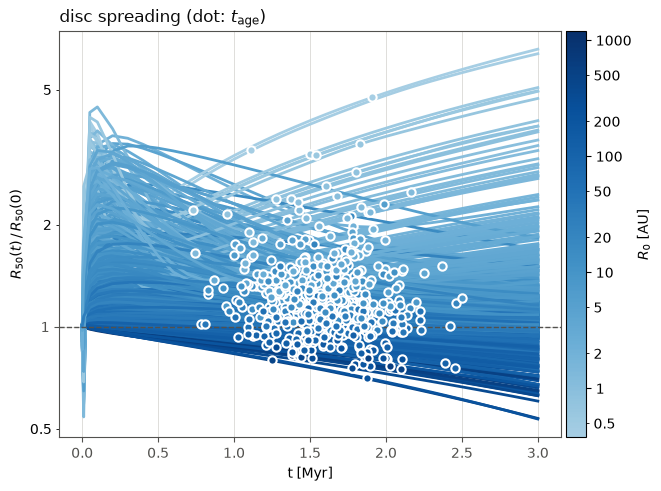

In [4]:
# =====================================================================================
# 2b. Figure: R50 growth
# =====================================================================================
import matplotlib.pyplot as plt
from matplotlib import colors as mcolors
from matplotlib.ticker import FuncFormatter, LogLocator, NullFormatter

INK, MUTED, GRID = "#0b0b0b", "#52514e", "#d9d8d4"    # text / reference lines / grid
cmap = mcolors.LinearSegmentedColormap.from_list("blues", plt.cm.Blues(np.linspace(0.35, 1.0, 256)))  # one hue, light->dark
norm = mcolors.LogNorm(vmin=comparisons.R0_au.min(), vmax=comparisons.R0_au.max())

fig, ax = plt.subplots(figsize=(6.5, 4.8), constrained_layout=True)   # single Axes, not an array
ax.grid(True, color=GRID, lw=0.6); ax.set_axisbelow(True)
for s in ax.spines.values(): s.set_color(MUTED)
ax.tick_params(colors=MUTED)

plain = FuncFormatter(lambda v, _: f"{v:g}")         # plain tick numbers on log axes
def tidy_log(ax, which="xy"):
    """Plain tick labels on log axes (call AFTER limits are set): decades always labelled;
    minor ticks at 2 and 5, labelled only when the axis spans < 2 decades."""
    for a, lims in ([(ax.xaxis, ax.get_xlim())] if "x" in which else []) + ([(ax.yaxis, ax.get_ylim())] if "y" in which else []):
        a.set_major_formatter(plain)
        a.set_minor_locator(LogLocator(base=10, subs=(2.0, 5.0)))
        a.set_minor_formatter(plain if np.log10(lims[1] / lims[0]) < 2 else NullFormatter())

# R50(t) / R50(0)
for disc_id, (ts, r50s) in r50_tracks.items():
    ts, r50s = np.asarray(ts), np.asarray(r50s)
    c = cmap(norm(draws.loc[disc_id, "R0_au"]))
    ax.plot(ts, r50s / r50s[0], color=c, lw=2)
    row = comparisons.loc[comparisons.id == disc_id].iloc[0]
    if np.isfinite(row.get("R50_growth", np.nan)):
        ax.plot(row.t_age_Myr, row.R50_growth, "o", ms=6, color=c, mec="white", mew=1.5, zorder=3)

ax.axhline(1, color=MUTED, ls="--", lw=1)
ax.set_yscale("log"); tidy_log(ax, "y")
ax.set_xlabel("t [Myr]"); ax.set_ylabel(r"$R_{50}(t)\,/\,R_{50}(0)$")
ax.set_title(r"disc spreading (dot: $t_{\rm age}$)", loc="left", color=INK)

cb = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, label=r"$R_0$ [AU]", pad=0.01)
cb.ax.yaxis.set_major_formatter(plain)
cb.ax.yaxis.set_minor_locator(LogLocator(base=10, subs=(2.0, 5.0)))
cb.ax.yaxis.set_minor_formatter(plain)
plt.show()

### 2c. Magnetic lever arm $\lambda$: Malanga's pure-wind model vs our hybrid model
**Equations.**

*Malanga et al. (2026), pure wind ($\psi \to \infty$).* The ejection index is defined as $\xi \equiv 1/[2(\lambda-1)]$ (text below their Eq. 5, p. 5), and related to $f_M$ by $1 + f_M = (R_0/R_{\rm in})^\xi$ (their Eq. 6), with $R_{\rm in} = 0.03$ AU. Hence
$$\lambda_{\rm pure} = 1 + \frac{1}{2\xi}, \qquad \xi = \frac{\ln(1+f_M)}{\ln(R_0/R_{\rm in})}.$$

*Our hybrid viscous + wind model (finite $\psi$).*
- The code's lever arm is Balogh et al. (2026) Eq. 16, $\lambda = 1 + \psi/[2(1-\epsilon_{\rm rad})(3+\psi)]$.
- Our $e_{\rm rad}$ mapping, $1-\epsilon_{\rm rad} = \xi(\psi+1+2\xi)/(\psi+3)$, makes this identical to the steady-state relation
$$\lambda_{\rm hyb} = 1 + \frac{\psi}{2\xi(\psi + 1 + 2\xi)}, \qquad \psi = \frac{\alpha_{\rm tot}}{\alpha_{SS}} - 1,\ \ \alpha_{SS} = 10^{-4}.$$
- **Comparing the two** at the same $\xi$: $(\lambda_{\rm hyb}-1)/(\lambda_{\rm pure}-1) = \psi/(\psi+1+2\xi)$, the fraction of the accretion driven by the wind torque. The hybrid disc therefore needs a slightly *shorter* lever arm (more mass lost per unit of angular momentum) to give the same $\xi$, because part of its accretion is viscous and removes no mass.

**Values plotted.** Each run's $\lambda$ follows exactly from the parameters that run was given (population CSV): its $R_0$, its $\psi$ (from its sampled $\alpha_{\rm tot}$), and $f_M = 10^{-0.6}$, which gives its $\xi$.
- $\lambda_{\rm hyb}$ is the CSV's `lambda_DW`, the value the code used (Balogh Eq. 16).
- $\lambda_{\rm pure}$ uses the same $\xi$.
- Dashed horizontal lines: the median $\lambda$ over the runs shown, blue for pure wind and orange for hybrid, with values in the legend.
- There are no error bars: a run's $\lambda$ is a definite number, not a measurement. The scatter between runs only reflects the spread of the sampled $R_0$ and $\alpha$ (Malanga Eq. 7).

**Lower panel.** The ratio $(\lambda_{\rm hyb}-1)/(\lambda_{\rm pure}-1) = \psi/(\psi+1+2\xi)$ for each run, with a dashed line at 1 (no difference). The two series in the upper panel differ by only a few percent, which is hard to see when 500 runs are plotted, so the ratio shows the difference directly.


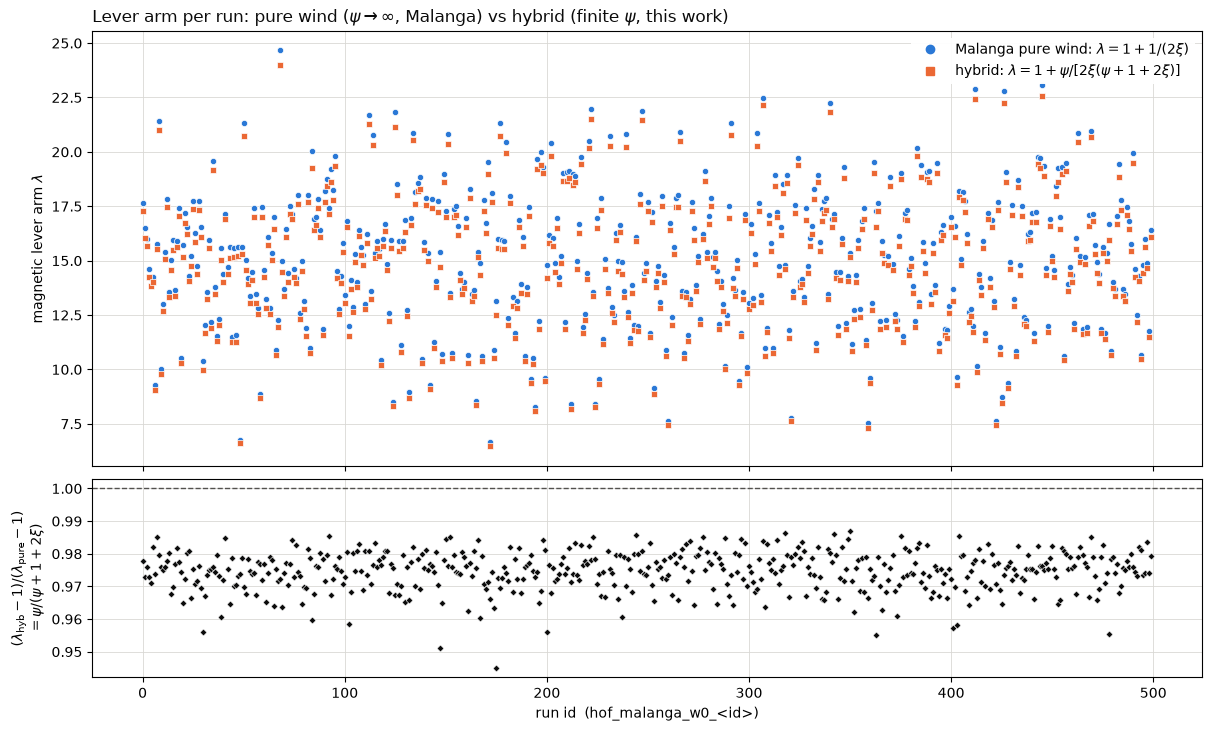

500 runs | lambda pure: median 15.2 (range 6.65-24.7) | lambda hybrid: median 14.8 (range 6.46-24)
(lambda_hyb - 1)/(lambda_pure - 1) = psi/(psi+1+2 xi): median 0.975, range 0.945-0.987


,id,R0_au,psi_DW,xi,lambda_pure,lambda_hyb,ratio_hyb_pure
0,0,52,46.7,0.03,17.6,17.3,0.978
1,1,30.9,38.1,0.0323,16.5,16.1,0.973
2,2,25.1,43.5,0.0333,16,15.7,0.976
3,3,13.3,38.6,0.0368,14.6,14.2,0.973
4,4,11.2,36,0.0379,14.2,13.8,0.971
...,...,...,...,...,...,...,...
495,495,14.6,39.4,0.0362,14.8,14.4,0.973
496,496,24.9,39.9,0.0333,16,15.6,0.974
497,497,15.2,63.9,0.036,14.9,14.7,0.984
498,498,3.74,41.1,0.0464,11.8,11.5,0.974


In [5]:
# =====================================================================================
# 2c. Lever arm lambda: Malanga pure-wind (psi -> inf) vs our hybrid model (finite psi), per run
#     (needs cell 1: draws, run_check). Equations: markdown cell above. Each run's lambda follows
#     exactly from its own sampled parameters (population CSV), so no error bars are drawn.
# =====================================================================================
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D


def lam_pure(xi):
    """Malanga pure-wind lever arm: xi = 1 / [2 (lambda - 1)]  (text below their Eq. 5)."""
    return 1.0 + 1.0 / (2.0 * xi)


ids = np.sort(run_check.id.to_numpy())                  # the runs in DATA_DIR
d = draws.loc[ids]
xi0 = d.xi.to_numpy()                                   # Malanga Eq. 6 with each run's R0 and f_M
lam_table = pd.DataFrame({"id": ids, "R0_au": d.R0_au.to_numpy(), "psi_DW": d.psi_DW.to_numpy(), "xi": xi0,
                          "lambda_pure": lam_pure(xi0),
                          "lambda_hyb": d.lambda_DW.to_numpy()})   # code's lambda (Balogh Eq. 16), CSV
lam_table["ratio_hyb_pure"] = (lam_table.lambda_hyb - 1) / (lam_table.lambda_pure - 1)  # = psi/(psi+1+2xi)

# ---- figure: top = lambda per run; bottom = ratio per run ----
C_PURE, C_HYB = "#2a78d6", "#eb6834"                   # categorical slots 1-2
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#d9d8d4"
fig, (ax, axr) = plt.subplots(2, 1, figsize=(12, 7.2), sharex=True, height_ratios=[2.2, 1],
                              constrained_layout=True)
for a in (ax, axr):
    a.grid(True, color=GRID, lw=0.6); a.set_axisbelow(True)
ax.plot(ids, lam_table.lambda_pure, "o", ms=4.5, color=C_PURE, mec="white", mew=0.5, ls="", zorder=3)
ax.plot(ids, lam_table.lambda_hyb, "s", ms=4, color=C_HYB, mec="white", mew=0.5, ls="", zorder=3)
# median lambda over the runs shown, one dashed line per model (same colour as its points)
med_pure, med_hyb = lam_table.lambda_pure.median(), lam_table.lambda_hyb.median()
ax.axhline(med_pure, color=C_PURE, ls="--", lw=1.4, zorder=2)
ax.axhline(med_hyb, color=C_HYB, ls="--", lw=1.4, zorder=2)
ax.set_ylabel(r"magnetic lever arm $\lambda$")
fig.suptitle(r"Lever arm per run: pure wind ($\psi\to\infty$, Malanga) vs hybrid (finite $\psi$, this work)",
             x=0.01, ha="left", color=INK)
ax.legend(handles=[
    Line2D([], [], marker="o", color=C_PURE, ls="", ms=6, label=r"Malanga pure wind: $\lambda = 1 + 1/(2\xi)$"),
    Line2D([], [], marker="s", color=C_HYB, ls="", ms=6, label=r"hybrid: $\lambda = 1 + \psi/[2\xi(\psi+1+2\xi)]$"),
    Line2D([], [], color=C_PURE, ls="--", lw=1.4, label=rf"median, pure wind ($\lambda$ = {med_pure:.3g})"),
    Line2D([], [], color=C_HYB, ls="--", lw=1.4, label=rf"median, hybrid ($\lambda$ = {med_hyb:.3g})")],
    loc="lower left", bbox_to_anchor=(0.0, 1.0), ncols=2, frameon=False)   # above the axes: hides no run
axr.plot(ids, lam_table.ratio_hyb_pure, "D", ms=3.5, color=INK, mec="white", mew=0.4, ls="", zorder=3)
axr.axhline(1.0, color=MUTED, ls="--", lw=1)
axr.set_ylabel(r"$(\lambda_{\rm hyb}-1)/(\lambda_{\rm pure}-1)$" "\n" r"$= \psi/(\psi+1+2\xi)$")
axr.set_xlabel("run id  (hof_malanga_w0_<id>)")
plt.show()

print(f"{len(ids)} runs | lambda pure: median {lam_table.lambda_pure.median():.3g} "
      f"(range {lam_table.lambda_pure.min():.3g}-{lam_table.lambda_pure.max():.3g}) | lambda hybrid: median "
      f"{lam_table.lambda_hyb.median():.3g} (range {lam_table.lambda_hyb.min():.3g}-{lam_table.lambda_hyb.max():.3g})")
print(f"(lambda_hyb - 1)/(lambda_pure - 1) = psi/(psi+1+2 xi): median {lam_table.ratio_hyb_pure.median():.3f}, "
      f"range {lam_table.ratio_hyb_pure.min():.3f}-{lam_table.ratio_hyb_pure.max():.3f}")
show_table(lam_table)


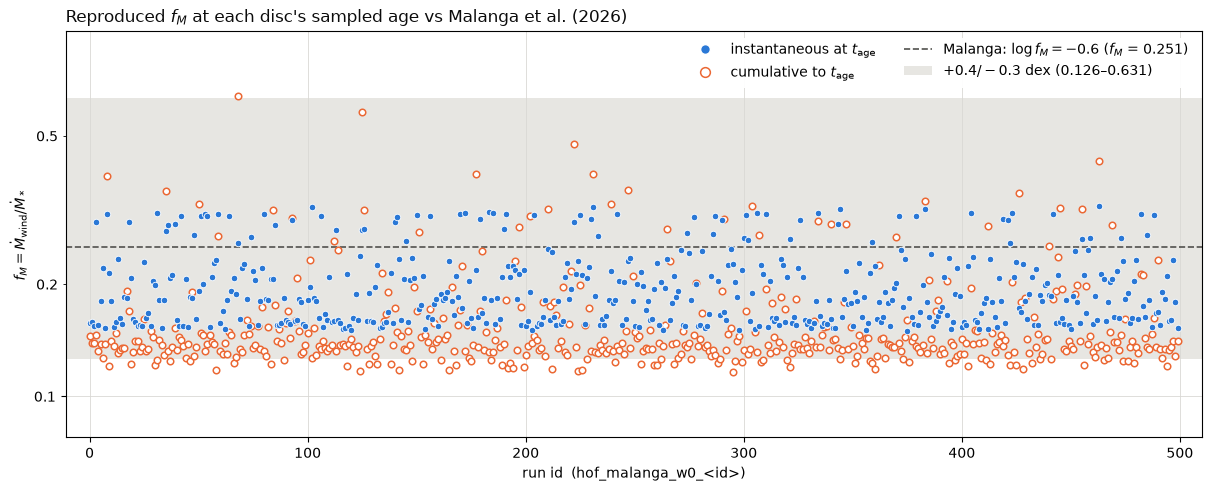

instantaneous: median 0.182 | inside band 500/500 | below 0 | above 0 (of which R0 beyond grid: 0)
cumulative   : median 0.138 | inside band 432/500 | below 67 | above 1 (of which R0 beyond grid: 1)


In [6]:
# =====================================================================================
# 2d. Reproduced f_M for every run vs Malanga's inferred f_M (needs cell 2: comparisons)
# =====================================================================================
# One point per disc (x = run id): the f_M our run actually produced at its sampled age t_age,
#   instantaneous  f_M,inst = Mdot_wind / Mdot_*  over a +-DT_WIN_MYR window around t_age   (cell 2)
#   cumulative     f_M,cum  = M_wind / M_acc      integrated from t = 0 to t_age             (cell 2)
# against the TARGET of our e_rad mapping, Malanga et al. (2026) Table 2 (MHD winds model):
#   log f_M = -0.6 (+0.4, -0.3)  [16th, 50th, 84th percentiles of the posterior; uncertainties in dex]
#   -> dashed line at f_M = 10^-0.6 = 0.251, shaded band 10^-0.9 = 0.126 to 10^-0.2 = 0.631.
# The y axis is logarithmic because Malanga's uncertainties are in log f_M.
# Notes:
#   * our grid starts at 0.1 AU (Malanga's R_in = 0.03 AU), so even a perfect steady-state run reaches
#     only f_M,grid = (R0/0.1 AU)^xi - 1 (~0.20 at the median), slightly below 0.251 (cell 2, f_M_expected);
#   * for discs with R0 beyond the grid, mass lost through the outer boundary is counted as "wind",
#     which inflates both f_M values (cell 2 caveat) -- they are counted separately in the summary.
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter, LogLocator, NullFormatter

LOG_FM_MALANGA = -0.6                    # Malanga et al. (2026) Table 2, MHD winds: median log f_M
LOG_FM_ERR_UP, LOG_FM_ERR_DOWN = 0.4, 0.3   # dex, to the 84th / 16th percentile
FM_TARGET = 10 ** LOG_FM_MALANGA                                     # 0.251
FM_LO, FM_HI = 10 ** (LOG_FM_MALANGA - LOG_FM_ERR_DOWN), 10 ** (LOG_FM_MALANGA + LOG_FM_ERR_UP)

fm = comparisons[["id", "beyond_grid", "fM_inst", "fM_cum"]].copy()
C_INST, C_CUM = "#2a78d6", "#eb6834"                  # same series colours as cell 2b
INK, MUTED, GRID, BAND = "#0b0b0b", "#52514e", "#d9d8d4", "#e7e6e2"

fig, ax = plt.subplots(figsize=(12, 4.8), constrained_layout=True)
ax.grid(True, color=GRID, lw=0.6); ax.set_axisbelow(True)
ax.axhspan(FM_LO, FM_HI, color=BAND, lw=0, zorder=0)
ax.axhline(FM_TARGET, color=MUTED, ls="--", lw=1.2, zorder=1)
ax.scatter(fm.id, fm.fM_inst, s=22, color=C_INST, edgecolor="white", lw=0.6, zorder=3)
ax.scatter(fm.id, fm.fM_cum, s=22, facecolor="white", edgecolor=C_CUM, lw=1.1, zorder=2)
ax.set_yscale("log")
vals = fm[["fM_inst", "fM_cum"]].to_numpy(dtype=float)
vals = vals[np.isfinite(vals) & (vals > 0)]
if vals.size:
    ax.set_ylim(min(vals.min(), FM_LO) / 1.5, max(vals.max(), FM_HI) * 1.5)
plain = FuncFormatter(lambda v, _: f"{v:g}")
ax.yaxis.set_major_formatter(plain)
ax.yaxis.set_minor_locator(LogLocator(base=10, subs=(2.0, 5.0)))
lo_, hi_ = ax.get_ylim()
ax.yaxis.set_minor_formatter(plain if np.log10(hi_ / lo_) < 2 else NullFormatter())
ax.set_xlim(fm.id.min() - 0.02 * (fm.id.max() - fm.id.min() + 1) - 1, fm.id.max() + 0.02 * (fm.id.max() - fm.id.min() + 1) + 1)
ax.set_xlabel("run id  (hof_malanga_w0_<id>)")
ax.set_ylabel(r"$f_M = \dot M_{\rm wind}/\dot M_*$")
ax.set_title(r"Reproduced $f_M$ at each disc's sampled age vs Malanga et al. (2026)", loc="left", color=INK)
ax.legend(handles=[
    Line2D([], [], marker="o", ls="", mfc=C_INST, mec="white", ms=7, label=r"instantaneous at $t_{\rm age}$"),
    Line2D([], [], marker="o", ls="", mfc="white", mec=C_CUM, mew=1.1, ms=7, label=r"cumulative to $t_{\rm age}$"),
    Line2D([], [], color=MUTED, ls="--", lw=1.2, label=rf"Malanga: $\log f_M = {LOG_FM_MALANGA}$ ($f_M$ = {FM_TARGET:.3f})"),
    Patch(facecolor=BAND, edgecolor="none", label=rf"$+{LOG_FM_ERR_UP}/-{LOG_FM_ERR_DOWN}$ dex ({FM_LO:.3f}–{FM_HI:.3f})")],
    loc="best", frameon=True, facecolor="white", edgecolor="none", framealpha=0.95, ncols=2)
plt.show()

# ---- summary: how many runs fall inside Malanga's 16-84% band ----
for col, lab in [("fM_inst", "instantaneous"), ("fM_cum", "cumulative")]:
    v = fm[col]; ok = v.notna()
    inside = ok & (v >= FM_LO) & (v <= FM_HI)
    print(f"{lab:13s}: median {v.median():.3g} | inside band {int(inside.sum())}/{int(ok.sum())} "
          f"| below {int((ok & (v < FM_LO)).sum())} | above {int((ok & (v > FM_HI)).sum())} "
          f"(of which R0 beyond grid: {int((ok & (v > FM_HI) & fm.beyond_grid).sum())})")
if fm.fM_inst.isna().any():
    print(f"no f_M (run does not reach t_age): ids {fm.id[fm.fM_inst.isna()].tolist()}")


## 3. Malanga et al. (2026) Fig. 4(b): the wind population in the $\dot M$–$M$ plane at the Lupus age
**What Fig. 4(b) shows** (Malanga et al. 2026, Sec. 4.3, p. 9–10): the best-fit MHD-wind synthetic population in the $\dot M$–$M$ plane.
- Each disc is read at its **own** age $t \sim N(\langle t\rangle, \sigma_t)$.
- Colour gives that age on a diverging green→pink scale, centred on the mean age: green = younger, pink = older.
- The black line is the **viscous isochrone** $M/\dot M = 2\,t_{\rm Lupus}$ (their Eq. 9 with $\gamma = 1$, $t \gg t_\nu$).

The paper's point is that the wind population shows **no age gradient** across this line, unlike the viscous one, and has a large spread in $M/\dot M$.

**This cell** builds the same plot for our DiscEvolution hybrid-wind population (cells 1–2):
- **Data:** $M$ = `disk_Mass`/M$_\odot$ and $\dot M$ = `disk_Mdot_star` (M$_\odot$/yr, at $R_c[0] \approx 0.11$ AU), interpolated from the time series (`t` in yr) at each disc's sampled $t_{\rm age}$ (population CSV).
- **Isochrone** uses `LUPUS_MEAN_AGE_MYR` = 1.6 Myr: the mean Lupus age Malanga infer for the wind model (their Table 2 and Sec. 4.3; the $t_{\rm Lupus}$ of their Fig. 4b), **not** the mean of our sampled ages. The literature HR-diagram age they quote is "typically 2 Myr" (Alcalá et al. 2017; Galli et al. 2020), available as an alternative.
- **Colour scale** is centred on the same 1.6 Myr.
- **Survival cut** (`APPLY_DETECTION_CUT`, default on): as in Malanga (Sec. 3, p. 5), discs with $M < 10^{-6}\,M_\odot$ or $\dot M < 10^{-12}\,M_\odot\,{\rm yr}^{-1}$ count as dispersed and are not plotted.
- **No observational scatter** is added; Fig. 4's caption does not mention any, unlike their Figs. 2 and 5.
- **Markers:** GI-flagged discs (cell 1) are **kept**, drawn as triangles instead of circles.
- **`PLOT_WITHOUT_GI = True`** additionally draws the same figure with the GI-flagged discs removed.
- **Axes:** Fig. 4's ranges (log $M$ −6 to −1, log $\dot M$ −12 to −7), widened automatically if any disc falls outside them.

**Differences from Malanga's population to keep in mind:**
- All our discs orbit a $1\,M_\odot$ star, whereas Malanga sample the Lupus stellar-mass function. Our points therefore sit at the high-$M$, high-$\dot M$ end.
- We have $\omega = 0$ (constant $\alpha$), against their $\omega = 0.4$.
- The temperature structure differs (the Step 3 sampler-test flag: initial $\dot M$ ≈ 2.2× the analytic estimate).


500 discs | run does not reach t_age: 0 | below the detection thresholds (dispersed): 35 | plotted: 465 (29 GI-flagged)


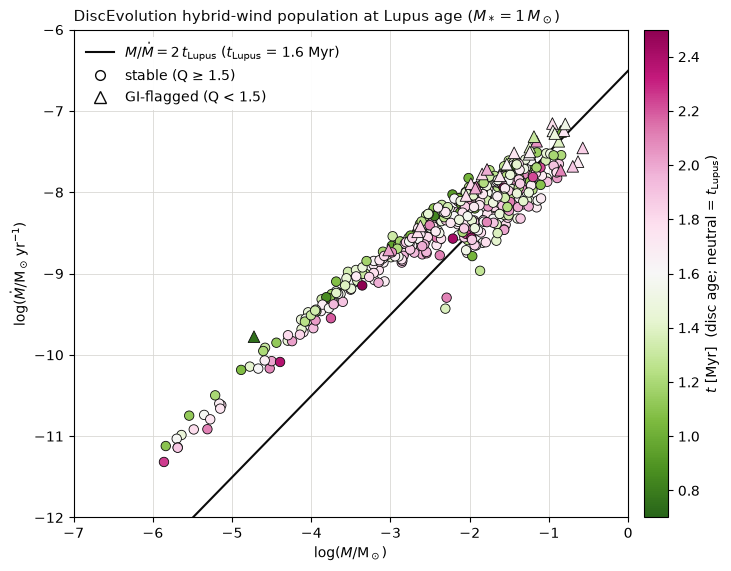

In [7]:
# =====================================================================================
# 3. Malanga et al. (2026) Fig. 4(b): Mdot - M at each disc's age, with the viscous isochrone
#    (needs cell 1: files, draws, run_check, show_table)
# =====================================================================================
import matplotlib.pyplot as plt
from matplotlib import colors as mcolors
from matplotlib.lines import Line2D
from DiscEvolution.constants import Msun                        # g

# ---- settings ------------------------------------------------------------------------
LUPUS_MEAN_AGE_MYR = 1.6     # Myr: Malanga et al. (2026) inferred mean Lupus age, MHD winds model
                             # (Table 2, Sec. 4.3; t_Lupus of their Fig. 4b). Literature alternative: 2.0
APPLY_DETECTION_CUT = True   # Malanga Sec. 3 (p. 5): discs below these are "dispersed" and not plotted
M_DETECT_MSUN = 1e-6         # Msun
MDOT_DETECT_MSUN_YR = 1e-12  # Msun / yr
PLOT_WITHOUT_GI = False      # True: ALSO draw the same figure with the GI-flagged discs removed
FIG4_XLIM, FIG4_YLIM = (-6, -1), (-12, -7)   # log M [Msun], log Mdot [Msun/yr]: Malanga Fig. 4 axes


def disc_at_age(path, d):
    """(M [Msun], Mdot [Msun/yr]) of one disc at its sampled age t_age (linear interpolation of
    the time series; t in yr). NaN if the run does not reach t_age."""
    with h5py.File(path, "r") as h:
        t = h["t"][:]                                     # yr
        M = h["disk_Mass"][:] / Msun                      # Msun
        Mdot = h["disk_Mdot_star"][:]                     # Msun / yr
    ta = d.t_age_Myr * 1e6                                # yr
    if len(t) < 2 or not (t[0] <= ta <= t[-1]):
        return np.nan, np.nan
    return float(np.interp(ta, t, M)), float(np.interp(ta, t, Mdot))


# ---- the population at the Lupus age --------------------------------------------------
rows = []
for f in files:
    disc_id = int(re.search(r"hof_malanga_w0_(\d+)_", os.path.basename(f)).group(1))
    d = draws.loc[disc_id]
    M_t, Mdot_t = disc_at_age(f, d)
    rows.append({"id": disc_id, "t_age_Myr": d.t_age_Myr, "M_Msun": M_t, "Mdot_Msun_yr": Mdot_t})
fig4 = pd.DataFrame(rows).merge(run_check[["id", "GI_flag"]], on="id", how="left")
fig4["GI_flag"] = fig4.GI_flag.fillna(False).astype(bool)

n_all = len(fig4)
covered = np.isfinite(fig4.M_Msun) & np.isfinite(fig4.Mdot_Msun_yr)
alive = covered & (fig4.M_Msun > 0) & (fig4.Mdot_Msun_yr > 0)       # logs need positive values
if APPLY_DETECTION_CUT:
    alive &= (fig4.M_Msun >= M_DETECT_MSUN) & (fig4.Mdot_Msun_yr >= MDOT_DETECT_MSUN_YR)
plot_df = fig4[alive].copy()
plot_df["logM"], plot_df["logMdot"] = np.log10(plot_df.M_Msun), np.log10(plot_df.Mdot_Msun_yr)
print(f"{n_all} discs | run does not reach t_age: {int((~covered).sum())} | "
      f"{'below the detection thresholds (dispersed)' if APPLY_DETECTION_CUT else 'non-positive M or Mdot'}: "
      f"{int((covered & ~alive).sum())} | plotted: {len(plot_df)} "
      f"({int(plot_df.GI_flag.sum())} GI-flagged)")


def fig4_scales(df):
    """Axis limits and age colour scale shared by every Fig. 4 plot, set from the FULL population
    `df` so the with- and without-GI figures are directly comparable.
    Axes: Fig. 4 ranges, widened (to whole dex) if any disc falls outside.
    Colour: diverging PiYG_r, neutral at the Lupus mean age (green younger, pink older), symmetric
    about it, at least +-0.8 Myr like Fig. 4(b) (0.8-2.4 Myr)."""
    if len(df):
        lims = (min(FIG4_XLIM[0], np.floor(df.logM.min() - 0.2)), max(FIG4_XLIM[1], np.ceil(df.logM.max() + 0.2)),
                min(FIG4_YLIM[0], np.floor(df.logMdot.min() - 0.2)), max(FIG4_YLIM[1], np.ceil(df.logMdot.max() + 0.2)))
        half = max(0.8, float(np.max(np.abs(df.t_age_Myr - LUPUS_MEAN_AGE_MYR))))
    else:
        lims, half = (*FIG4_XLIM, *FIG4_YLIM), 0.8
    norm = mcolors.TwoSlopeNorm(vcenter=LUPUS_MEAN_AGE_MYR,
                                vmin=LUPUS_MEAN_AGE_MYR - half, vmax=LUPUS_MEAN_AGE_MYR + half)
    return lims, norm


def plot_fig4(df, title, lims, norm, color_col="t_age_Myr", cmap=None,
              cbar_label=r"$t$ [Myr]  (disc age; neutral = $t_{\rm Lupus}$)"):
    """Malanga Fig. 4(b)-style plot of `df` (columns logM, logMdot, GI_flag and `color_col`), with the
    shared axis limits `lims` = (xlo, xhi, ylo, yhi) and colour scale `norm` (fig4_scales).
    By default the points are coloured by the disc age (Malanga's Fig. 4b); `color_col` / `cmap` /
    `cbar_label` colour them by another column instead (cell 3b: psi_DW). Everything else is identical."""
    INK, GRID = "#0b0b0b", "#d9d8d4"
    cmap = plt.cm.PiYG_r if cmap is None else cmap
    xlo, xhi, ylo, yhi = lims

    fig, ax = plt.subplots(figsize=(7.2, 5.6), constrained_layout=True)
    ax.grid(True, color=GRID, lw=0.6); ax.set_axisbelow(True)
    # viscous isochrone M / Mdot = 2 t_Lupus  ->  log Mdot = log M - log(2 t_Lupus [yr])
    xs = np.array([xlo, xhi])
    ax.plot(xs, xs - np.log10(2 * LUPUS_MEAN_AGE_MYR * 1e6), color=INK, lw=1.5, zorder=1)
    sc = None
    for marker, sel, size in [("o", ~df.GI_flag, 46), ("^", df.GI_flag, 70)]:
        if sel.any():
            sc = ax.scatter(df.logM[sel], df.logMdot[sel], c=df[color_col][sel], cmap=cmap, norm=norm,
                            marker=marker, s=size, edgecolor=INK, linewidths=0.6, zorder=3)
    ax.set_xlim(xlo, xhi); ax.set_ylim(ylo, yhi)
    ax.set_xlabel(r"$\log(M/{\rm M_\odot})$"); ax.set_ylabel(r"$\log(\dot M/{\rm M_\odot\,yr^{-1}})$")
    ax.set_title(title, loc="left", color=INK, fontsize=11)
    handles = [Line2D([], [], color=INK, lw=1.5,
                      label=rf"$M/\dot M = 2\,t_{{\rm Lupus}}$ ($t_{{\rm Lupus}}$ = {LUPUS_MEAN_AGE_MYR:g} Myr)"),
               Line2D([], [], marker="o", ls="", mfc="white", mec=INK, ms=7, label="stable (Q ≥ 1.5)")]
    if df.GI_flag.any():
        handles.append(Line2D([], [], marker="^", ls="", mfc="white", mec=INK, ms=8, label="GI-flagged (Q < 1.5)"))
    ax.legend(handles=handles, loc="upper left", frameon=True, facecolor="white", edgecolor="none", framealpha=0.95)
    cb = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, pad=0.02)
    cb.set_label(cbar_label)
    plt.show()


fig4_lims, fig4_norm = fig4_scales(plot_df)          # shared by both figures below
plot_fig4(plot_df, "DiscEvolution hybrid-wind population at Lupus age ($M_* = 1\\,M_\\odot$)", fig4_lims, fig4_norm)
if PLOT_WITHOUT_GI:
    no_gi = plot_df[~plot_df.GI_flag]
    print(f"Without GI-flagged discs: {len(no_gi)} plotted ({int(plot_df.GI_flag.sum())} removed)")
    plot_fig4(no_gi, "Same, GI-flagged discs removed (same axes and colour scale)", fig4_lims, fig4_norm)


psi_DW of the 465 plotted discs: min 18.5, median 42, max 80.6


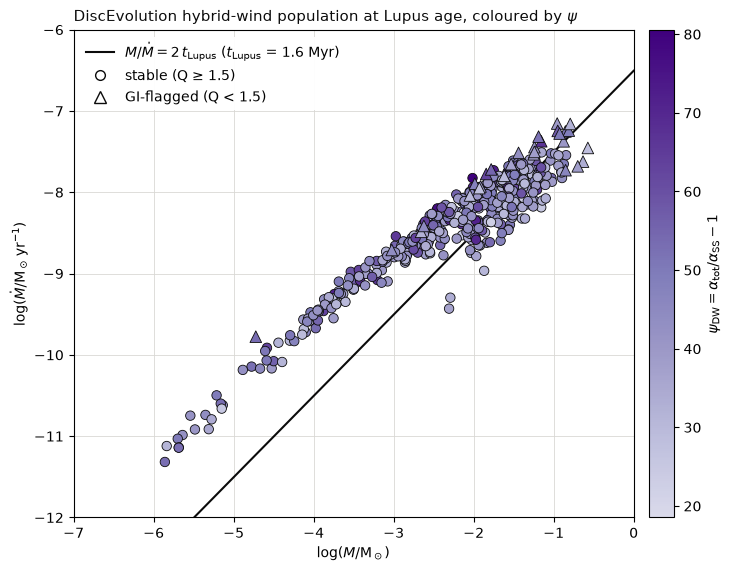

In [8]:
# =====================================================================================
# 3b. Same Fig. 4(b) plot, coloured by psi_DW instead of disc age (needs cell 3)
# =====================================================================================
# IDENTICAL to cell 3 -- same discs (plot_df: same survival cut), same axes (fig4_lims), same
# isochrone M/Mdot = 2 t_Lupus, same markers (triangles = GI-flagged) -- except the colour, which is
# the disc's wind parameter psi_DW = alpha_tot / alpha_SS - 1 [dimensionless] (population CSV).
# Why psi: with alpha_SS fixed at 1e-4, psi sets the TOTAL alpha (alpha_tot = alpha_SS (1 + psi)) and
# hence the accretion timescale, so if the position relative to the isochrone tracks psi, the
# M/Mdot spread is driven by the sampled alpha_DW rather than by age.
# Colour scale: sequential (one hue, light = low psi -> dark = high psi), linear over the psi range of
# the plotted discs. PLOT_WITHOUT_GI (cell 3) also applies here.
from matplotlib import colors as mcolors
import inspect

# Stale-kernel check: this cell needs cell 3's CURRENT plot_fig4 (with the color_col argument). If the
# kernel still holds an older definition (cell 3 not re-run since the notebook was updated), stop with
# a clear message instead of a TypeError.
if "color_col" not in inspect.signature(plot_fig4).parameters:
    raise RuntimeError("plot_fig4 in this kernel is an OLD version: reload the notebook from disk "
                       "(VS Code: close/reopen or 'Revert File'), then re-run cell 3 before this cell.")

psi_df = plot_df.merge(draws[["psi_DW"]], left_on="id", right_index=True, how="left")
psi_cmap = mcolors.LinearSegmentedColormap.from_list("psi", plt.cm.Purples(np.linspace(0.25, 1.0, 256)))
psi_norm = (mcolors.Normalize(vmin=psi_df.psi_DW.min(), vmax=psi_df.psi_DW.max()) if len(psi_df)
            else mcolors.Normalize(vmin=0, vmax=1))
print(f"psi_DW of the {len(psi_df)} plotted discs: min {psi_df.psi_DW.min():.3g}, "
      f"median {psi_df.psi_DW.median():.3g}, max {psi_df.psi_DW.max():.3g}")
psi_label = r"$\psi_{\rm DW} = \alpha_{\rm tot}/\alpha_{\rm SS} - 1$"

plot_fig4(psi_df, "DiscEvolution hybrid-wind population at Lupus age, coloured by $\\psi$",
          fig4_lims, psi_norm, color_col="psi_DW", cmap=psi_cmap, cbar_label=psi_label)
if PLOT_WITHOUT_GI:
    plot_fig4(psi_df[~psi_df.GI_flag], "Same, GI-flagged discs removed (same axes and colour scale)",
              fig4_lims, psi_norm, color_col="psi_DW", cmap=psi_cmap, cbar_label=psi_label)


## 4. Per-$M_\star$ population (pilot): how is $\psi$ distributed?
*(Hof, 2026-10-28)* A second population, `sample_malanga_mstar_Hof.py` (N = 500, seed 1). Each disc has **its own star**:
- $M_\star$ is resampled from the 65 measured masses of Malanga et al. (2026) Table A.1. *(2026-10-29)* Only masses in **0.1–1.5 $M_\odot$** are kept: a draw outside that range is redrawn. Table A.1 has 17 masses below 0.1 $M_\odot$ (none above 1.5), so 132 of the 500 discs got a new star (column `flag_Mstar_redrawn`); the other 368 discs are unchanged.
- $R_\star$ and $T_{\rm eff}$ come from the BHAC15 0.5 Myr isochrone.
- $M_0$, $R_0$ and $\alpha$ come from Malanga Eq. 7 at that $M_\star$ (Table 2, MHD column).
- The inner grid edge $r_{\rm min}$ is the Königl (1991, Eq. 1) magnetospheric truncation radius ($B_\star = 0.5$ kG, $\beta = 0.5$). It is floored at 0.03 au and capped at 0.1 au (*2026-10-28*; the cap was $0.16\,R_0$ before, which the $\alpha_{\rm SS} = 10^{-4}$ pilot used).
- *(2026-10-29)* The outer grid edge is $r_{\rm max} = \min(20\,R_0, 1000$ au$)$ (was $400\,R_0$).

**Two values of $\alpha_{\rm SS}$** *(2026-10-28)*:
- The **22-disc pilot** (Nibi job 25134509) was run with $\alpha_{\rm SS} = 10^{-4}$. Its outputs and the CSV it used are in `popsynth/malanga_mstar`.
- The population was then **redrawn with $\alpha_{\rm SS} = 10^{-5}$** (same seed, so every disc keeps its $M_\star$, $M_0$, $R_0$ and $\alpha$; only $\psi$ and what follows from it change). New runs go to `popsynth/malanga_mstar_aSS1e-5`.
- *(2026-10-29)* The second pilot (22 discs + disc 279, $\alpha_{\rm SS} = 10^{-5}$) was run with the population **before** the $M_\star$ restriction and the $20\,R_0$ grid edge. Its own copy of the CSV in its output folder keeps what it was run with; the repo CSV is now the restricted population.

**What $\psi$ is.** Malanga's $\alpha_{\rm DW}$ is our *total* $\tilde\alpha = \alpha_{\rm DW} + \alpha_{\rm SS}$ (Tabone et al. 2022, Eq. 12), with $\psi \equiv \alpha_{\rm DW}/\alpha_{\rm SS}$ (Tabone Eq. 13). With $\alpha_{\rm SS}$ fixed for every disc,
$$\psi_{\rm raw} = \frac{\alpha}{\alpha_{\rm SS}} - 1 .$$

**Why $\psi_{\rm raw}$ can be negative.** Malanga's median $\alpha$ rises steeply with stellar mass, $\log\bar\alpha = -3.4 + 2.0\log(M_\star/0.3\,M_\odot)$. It falls below $\alpha_{\rm SS}$ for $M_\star \lesssim 0.3\times10^{(\log\alpha_{\rm SS}+3.4)/2}\,M_\odot$ (0.15 $M_\odot$ for $\alpha_{\rm SS} = 10^{-4}$, 0.048 $M_\odot$ for $10^{-5}$), which gives $\psi_{\rm raw} < 0$, and that is unphysical. *(2026-10-29)* With $M_\star \geq 0.1\,M_\odot$ and $\alpha_{\rm SS} = 10^{-5}$ no disc has $\psi_{\rm raw} < 0$ any more (0.1 $M_\odot$ is 0.32 dex above 0.048 $M_\odot$, i.e. $\alpha$ is 0.65 dex ≈ 6.5$\sigma$ above $\alpha_{\rm SS}$ at the median). Those discs were run with the floor $\psi_{\rm DW} = \max(\psi_{\rm raw}, 0)$, so they are purely viscous with no wind ($e_{\rm rad} = 1$, $\lambda = \infty$).

**Threshold $\psi = 10$.** This is an arbitrary marker for the transition to wind-dominated discs. At $\psi = 10$ the wind torque is ten times the viscous torque (Tabone Eq. 13).

Cell 4 loads the population and, *if they are on this machine*, the pilot runs (*2026-10-29*: the population loads even when `MSTAR_DIR` is empty or missing); it does not need cells 1–3. Cell 4b draws the histogram of $\psi_{\rm raw}$ for **all 500 drawn discs of the CURRENT population** (the repo CSV, $\alpha_{\rm SS} = 10^{-5}$), not just the 22 that were run.

In [7]:
# =====================================================================================
# 4. Per-M* population ("mstar"): load the population CSV and the PILOT runs
#    (Hof, 2026-10-28) SELF-CONTAINED: does not need cells 1-3, so it also runs on a machine
#    without the 1 Msun data (DATA_DIR of cell 1). Variables end in _ms so nothing above is overwritten.
# =====================================================================================
# Population: sample_malanga_mstar_Hof.py, N = 500, seed 1 (copy written into the output folder by
#   run_popsynth_malanga_Hof.sh). Per disc: M* from Malanga et al. (2026) Table A.1, R* and Teff from
#   the BHAC15 0.5 Myr isochrone, M0 / R0 / alpha from Malanga Eq. 7 at that M*, r_min from the
#   Konigl (1991) truncation radius (B* = 0.5 kG), alpha_SS fixed (1e-5 since 2026-10-28, was 1e-4).
#   (2026-10-29) M* restricted to 0.1-1.5 Msun (draws outside redrawn; flag_Mstar_redrawn) and
#   r_max = min(20 R0, 1000 au) (was 400 R0). Only the REPO CSV (pop_ms) has these changes.
# Pilot: 22 discs run on Nibi (Slurm job 25134509) with alpha_SS = 1e-4, copied to MSTAR_DIR with rsync.
# (Hof, 2026-10-28) The population was then REDRAWN with alpha_SS = 1e-5 (same seed). Two tables:
#   draws_ms  the CSV the pilot runs were MADE with (copy in MSTAR_DIR, alpha_SS = 1e-4) -> pilot_ms
#   pop_ms    the CURRENT population CSV in the repo (POP_CSV_MS, alpha_SS = 1e-5)    -> histogram (cell 4b)
# Keeping them apart means each run is joined to the psi it actually used.
# (Hof, 2026-10-29) MSTAR_DIR now points at the alpha_SS = 1e-5 pilot folder, and the pilot part is
# OPTIONAL: if MSTAR_DIR has no population CSV or no .h5 files (e.g. not copied from Nibi yet), only
# pop_ms is loaded, draws_ms = None and pilot_ms is an EMPTY table, so cell 4b still runs.
# Columns of pilot_ms (one row per .h5 file):
#   id          disc id (row of the population CSV; run_name = hof_malanga_w0_<id>)
#   Mstar_Msun  stellar mass [Msun]                                     (population CSV)
#   R0_au       characteristic radius R0 [AU]                           (population CSV)
#   psi_raw     alpha / alpha_SS - 1, BEFORE the floor [dimensionless]  (population CSV)
#   psi_DW      max(psi_raw, 0), the value the run used [dimensionless] (population CSV)
#   rmin_au     inner grid edge [AU]                                    (population CSV)
#   t_last_Myr  last snapshot time_snap[-1] [Myr]                       (HDF5)
#   complete    HDF5 attr complete = True AND t_last_Myr reached T_END_MYR_MS. Both are needed:
#               run_model_Hof.py also sets complete = True when a run CRASHES (finally block)
#   runtime_h   wall-clock run_end - run_start [h] (HDF5 attrs; includes set-up)
#   GI_flag     Toomre Q < 1.5 somewhere in the INITIAL disc (Balogh et al. 2026, Eq. 48; HDF5 attr)
import os, glob, re
from datetime import datetime
import numpy as np
import pandas as pd
import h5py

# (2026-10-29) was .../popsynth/malanga_mstar (the alpha_SS = 1e-4 pilot, deleted). Pilot 2 (alpha_SS = 1e-5,
# population BEFORE the 2026-10-29 changes) lives in malanga_mstar_aSS1e-5 on Nibi scratch; rsync it here to load it.
MSTAR_DIR = "/home/imontesd/output/DiscEvolution/popsynth/malanga_mstar_aSS1e-5"   # local copy of a Nibi pilot
POP_CSV_MS = os.path.abspath(os.path.join(os.getcwd(), "..", "config", "malanga",          # notebook is in StartHere/notebooks/
                                          "malanga_mstar_draws_Hof_N500_seed1.csv"))     # current population (alpha_SS = 1e-5)
T_END_MYR_MS = 3.0       # Myr, last snapshot of DiscConfig_Hof_malanga_mstar.json
T_END_RTOL_MS = 1e-3     # relative tolerance for "reached the end" (dimensionless)

# ---- the CURRENT population (all 500 discs, whether run or not); always loaded ----
pop_ms = pd.read_csv(POP_CSV_MS).set_index("id")         # CURRENT population (histogram, cell 4b)

# ---- the PILOT: its own population CSV + one .h5 per disc; OPTIONAL (2026-10-29) ----
csvs_ms = glob.glob(os.path.join(MSTAR_DIR, "malanga_mstar_draws_Hof_*.csv"))     # [] if MSTAR_DIR is missing
files_ms = sorted(glob.glob(os.path.join(MSTAR_DIR, "hof_malanga_w0_*.h5")))
assert len(csvs_ms) <= 1, f"expected at most one malanga_mstar_draws_Hof_*.csv in {MSTAR_DIR}, found {csvs_ms}"
HAVE_PILOT_MS = bool(csvs_ms) and bool(files_ms)       # True only if the pilot was copied to MSTAR_DIR
draws_ms = pd.read_csv(csvs_ms[0]).set_index("id") if HAVE_PILOT_MS else None   # population the PILOT was run with
if not HAVE_PILOT_MS:
    files_ms = []                                      # skip the loop below; pilot_ms is then empty
    print(f"NOTE: no pilot population CSV + .h5 files in {MSTAR_DIR}; loading the population CSV only.")

rows_ms = []
for path in files_ms:
    disc_id = int(re.search(r"hof_malanga_w0_(\d+)_", os.path.basename(path)).group(1))
    d = draws_ms.loc[disc_id]
    with h5py.File(path, "r") as h:
        a = h.attrs
        t_last = float(h["time_snap"][-1]) if ("time_snap" in h and len(h["time_snap"])) else np.nan   # Myr
        runtime = np.nan
        if "run_start" in a and "run_end" in a:
            runtime = (datetime.fromisoformat(str(a["run_end"]))
                       - datetime.fromisoformat(str(a["run_start"]))).total_seconds() / 3600       # h
        rows_ms.append({
            "id": disc_id, "Mstar_Msun": d.Mstar_Msun, "R0_au": d.R0_au,
            "psi_raw": d.psi_raw, "psi_DW": d.psi_DW, "rmin_au": d.rmin_au,
            "t_last_Myr": t_last,
            "complete": bool(a.get("complete", False)) and bool(t_last >= T_END_MYR_MS * (1 - T_END_RTOL_MS)),
            "runtime_h": runtime,
            "GI_flag": bool(a.get("GI_flag", False)),
        })
# (2026-10-29) explicit columns, so an EMPTY pilot_ms (no pilot copied) still has them
PILOT_COLS_MS = ["id", "Mstar_Msun", "R0_au", "psi_raw", "psi_DW", "rmin_au", "t_last_Myr",
                 "complete", "runtime_h", "GI_flag"]
pilot_ms = (pd.DataFrame(rows_ms, columns=PILOT_COLS_MS)
            .sort_values("R0_au").reset_index(drop=True))                     # compact discs first

print(f"Current population: {len(pop_ms)} discs, alpha_SS = {pop_ms.alpha_SS.unique()}, "
      f"M* = {pop_ms.Mstar_Msun.min():.3g}-{pop_ms.Mstar_Msun.max():.3g} Msun (median {pop_ms.Mstar_Msun.median():.3g}), "
      f"{int(pop_ms.get('flag_Mstar_redrawn', pd.Series(0)).sum())} M* redrawn into 0.1-1.5 Msun  ({POP_CSV_MS})")
if HAVE_PILOT_MS:
    print(f"Pilot population:   {len(draws_ms)} discs, alpha_SS = {draws_ms.alpha_SS.unique()}  (copy in MSTAR_DIR)")
    print(f"Pilot:      {len(pilot_ms)} runs in {MSTAR_DIR}  |  complete: {int(pilot_ms.complete.sum())}  |  "
          f"GI-flagged (Q < 1.5): {int(pilot_ms.GI_flag.sum())}  |  runtime median "
          f"{pilot_ms.runtime_h.median():.2f} h, max {pilot_ms.runtime_h.max():.2f} h")
pilot_ms.round({"Mstar_Msun": 4, "R0_au": 4, "psi_raw": 4, "psi_DW": 4, "rmin_au": 4, "runtime_h": 2})

NOTE: no pilot population CSV + .h5 files in /home/imontesd/output/DiscEvolution/popsynth/malanga_mstar_aSS1e-5; loading the population CSV only.
Current population: 500 discs, alpha_SS = [1.e-05], M* = 0.1-1.26 Msun (median 0.234), 132 M* redrawn into 0.1-1.5 Msun  (/home/imontesd/DiscEvolution/example/StartHere/config/malanga/malanga_mstar_draws_Hof_N500_seed1.csv)


,id,Mstar_Msun,R0_au,psi_raw,psi_DW,rmin_au,t_last_Myr,complete,runtime_h,GI_flag


psi_raw of all N = 500 discs: min 1.72, median 23.8, max 1.15e+03
  psi_raw < 0              :   0 / 500 ( 0.0 %)  -> floored to psi_DW = 0 (purely viscous, no wind)
  psi_raw < 10             : 145 / 500 (29.0 %)  (includes the 0 negative values)
    of which 0 <= psi_raw < 10: 145 / 500 (29.0 %)  (wind on, but weaker than 10x the viscous torque)
  psi_raw >= 10            : 355 / 500 (71.0 %)  (wind-dominated)
  stellar masses: psi_raw < 0 for M* = none; psi_raw >= 0 for M* = 0.1-1.26 Msun
  (Malanga Eq. 7: the MEDIAN alpha equals alpha_SS = 1e-05 at M* = 0.048 Msun; the 0.1 dex scatter blurs that boundary)


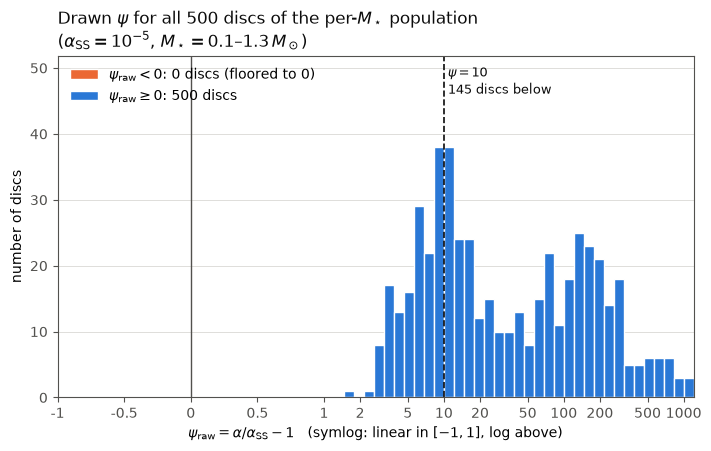

In [8]:
# =====================================================================================
# 4b. Histogram of psi_raw for ALL 500 discs of the CURRENT per-M* population (needs cell 4: pop_ms)
# =====================================================================================
# psi_raw = alpha / alpha_SS - 1  [dimensionless], one value per disc in the population CSV
#   alpha     = Malanga's alpha_DW (Eq. 7, Table 2) = our TOTAL alpha = alpha_DW + alpha_SS
#               (Tabone et al. 2022, Eq. 12), so psi = alpha_DW / alpha_SS (Tabone Eq. 13)
#   alpha_SS  = the same for every disc; read from the CSV (1e-5 since 2026-10-28, was 1e-4)
# psi_raw < 0 (alpha below alpha_SS) is unphysical: those discs were run with the FLOOR
# psi_DW = max(psi_raw, 0), i.e. purely viscous, no wind (e_rad = 1, lambda = inf).
# These are the values DRAWN for all 500 discs, not only the 22 pilot runs.
# (Hof, 2026-10-29) With M* restricted to 0.1-1.5 Msun no disc has psi_raw < 0 (n_neg = 0): the orange
# histogram is then empty and its legend entry reads "0 discs"; the M* prints below handle n_neg = 0.
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

PSI_WINDY = 10.0   # dimensionless; ARBITRARY threshold (user's choice) for the transition to
                   # wind-dominated discs: psi = 10 means the wind torque is 10x the viscous one
                   # (psi = alpha_DW / alpha_SS, Tabone et al. 2022 Eq. 13)

INK, MUTED, GRID = "#0b0b0b", "#52514e", "#d9d8d4"   # text / reference lines / grid (as in cell 2b)
C_NEG, C_POS = "#eb6834", "#2a78d6"                  # orange: psi_raw < 0 (floored); blue: psi_raw >= 0

aSS_values = pop_ms["alpha_SS"].unique()
assert aSS_values.size == 1, f"alpha_SS is not the same for every disc: {aSS_values}"
ALPHA_SS_MS = float(aSS_values[0])                    # dimensionless, the fixed viscous alpha of this population
psi_raw_all = pop_ms["psi_raw"].to_numpy()            # dimensionless, all discs
Mstar_all = pop_ms["Mstar_Msun"].to_numpy()           # Msun
n_all = psi_raw_all.size
neg = psi_raw_all < 0                                 # floored to psi_DW = 0 in the runs
below_windy = psi_raw_all < PSI_WINDY                 # includes the negative ones

# ---- counts ----
n_neg = int(neg.sum())
n_below = int(below_windy.sum())
n_0_to_windy = int(((psi_raw_all >= 0) & below_windy).sum())
n_windy = n_all - n_below
pct = lambda k: 100.0 * k / n_all
print(f"psi_raw of all N = {n_all} discs: min {psi_raw_all.min():.3g}, median {np.median(psi_raw_all):.3g}, "
      f"max {psi_raw_all.max():.3g}")
print(f"  psi_raw < 0              : {n_neg:3d} / {n_all} ({pct(n_neg):4.1f} %)  -> floored to psi_DW = 0 "
      f"(purely viscous, no wind)")
print(f"  psi_raw < {PSI_WINDY:g}             : {n_below:3d} / {n_all} ({pct(n_below):4.1f} %)  "
      f"(includes the {n_neg} negative values)")
print(f"    of which 0 <= psi_raw < {PSI_WINDY:g}: {n_0_to_windy:3d} / {n_all} ({pct(n_0_to_windy):4.1f} %)  "
      f"(wind on, but weaker than {PSI_WINDY:g}x the viscous torque)")
print(f"  psi_raw >= {PSI_WINDY:g}            : {n_windy:3d} / {n_all} ({pct(n_windy):4.1f} %)  (wind-dominated)")
# (2026-10-29) M* range of each group; "none" when a group is empty (min() of an empty array would fail)
m_range = lambda m: f"{m.min():.3g}-{m.max():.3g} Msun" if m.size else "none"
print(f"  stellar masses: psi_raw < 0 for M* = {m_range(Mstar_all[neg])}; "
      f"psi_raw >= 0 for M* = {m_range(Mstar_all[~neg])}")
# Malanga Eq. 7 median: log10 alpha = -3.4 + 2.0 log10(M*/0.3) (Table 2, MHD) equals log10 alpha_SS at
# log10(M*/0.3) = (log10 alpha_SS - (-3.4)) / 2.0  (= -0.8, i.e. M* = 0.048 Msun, for alpha_SS = 1e-5)
Mstar_psi0 = 0.3 * 10 ** ((np.log10(ALPHA_SS_MS) - (-3.4)) / 2.0)              # Msun
print(f"  (Malanga Eq. 7: the MEDIAN alpha equals alpha_SS = {ALPHA_SS_MS:g} at M* = {Mstar_psi0:.3f} Msun; "
      f"the 0.1 dex scatter blurs that boundary)")

# ---- bins ----
# psi_raw spans -1 (alpha -> 0) to ~100 (alpha_SS = 1e-4) or ~1000 (1e-5), so the x axis is symlog: LINEAR in [-1, 1], LOG above 1.
# Bin edges: 0.1 wide in [-1, 1], then log-spaced (~12 per decade) above 1, so every bin has
# roughly the same width on screen. 0 is an exact edge, so no bin mixes negative and positive values.
# Bar heights are COUNTS per bin.
edges_lin = np.linspace(-1.0, 1.0, 21)                                         # includes 0 exactly
top = 10 ** (np.ceil(np.log10(psi_raw_all.max()) * 12) / 12)                  # first log edge >= max
edges_log = np.logspace(0.0, np.log10(top), int(round(np.log10(top) * 12)) + 1)[1:]
edges = np.concatenate([edges_lin, edges_log])
assert psi_raw_all.min() >= edges[0] and psi_raw_all.max() <= edges[-1], "psi_raw outside the bin range"

fig, ax = plt.subplots(figsize=(7.0, 4.4), constrained_layout=True)
ax.grid(True, axis="y", color=GRID, lw=0.6); ax.set_axisbelow(True)
for s in ax.spines.values(): s.set_color(MUTED)
ax.tick_params(colors=MUTED)

ax.hist(psi_raw_all[neg], bins=edges, color=C_NEG, edgecolor="white", linewidth=1.0,
        label=rf"$\psi_{{\rm raw}} < 0$: {n_neg} discs (floored to 0)")
ax.hist(psi_raw_all[~neg], bins=edges, color=C_POS, edgecolor="white", linewidth=1.0,
        label=rf"$\psi_{{\rm raw}} \geq 0$: {n_all - n_neg} discs")

ax.set_xscale("symlog", linthresh=1.0, linscale=1.0)
ticks = [t for t in [-1, -0.5, 0, 0.5, 1, 2, 5, 10, 20, 50, 100, 200, 500, 1000, 2000] if t <= edges[-1]]
ax.set_xticks(ticks)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
ax.set_xlim(edges[0], edges[-1])

ax.set_ylim(0, ax.get_ylim()[1] * 1.3)          # 30 % headroom: the legend and the psi = 10 label sit ABOVE the bars
ax.axvline(0.0, color=MUTED, lw=1.0)                                            # floor
ax.axvline(PSI_WINDY, color=INK, lw=1.2, ls="--")                               # windy threshold
ax.text(PSI_WINDY * 1.08, 0.97, rf"$\psi = {PSI_WINDY:g}$" + "\n" + f"{n_below} discs below",
        transform=ax.get_xaxis_transform(), va="top", ha="left", color=INK, fontsize=9)

ax.set_xlabel(r"$\psi_{\rm raw} = \alpha/\alpha_{\rm SS} - 1$   (symlog: linear in $[-1, 1]$, log above)")
ax.set_ylabel("number of discs")
# (2026-10-29) title also gives the M* range of the population [Msun]; two lines so it fits the figure
ax.set_title(rf"Drawn $\psi$ for all {n_all} discs of the per-$M_\star$ population" + "\n" +
             rf"($\alpha_{{\rm SS}} = 10^{{{np.log10(ALPHA_SS_MS):.0f}}}$, "
             rf"$M_\star = {Mstar_all.min():.2g}$–${Mstar_all.max():.2g}\,M_\odot$)", loc="left", color=INK)
ax.legend(frameon=False, loc="upper left")                                   # in the headroom, top left
plt.show()

### 4c. Same 500 discs, two values of $\alpha_{\rm SS}$: how does the $\psi$ distribution change?
*(Hof, 2026-10-29)* `malanga_mstar_draws_Hof_N500_seed1_aSS1e-4.csv` is the **same population** as the repo CSV (same seed: every disc has the same $M_\star$, $M_0$, $R_0$ and total $\alpha$), drawn with $\alpha_{\rm SS} = 10^{-4}$ instead of $10^{-5}$. It is for analysis only; the launchers still use the $10^{-5}$ file.

**Is it a one-order-of-magnitude shift?** Only for $1+\psi$, not for $\psi$ itself. The total viscosity is $\tilde\alpha = \alpha_{\rm SS} + \alpha_{\rm DW} = \alpha_{\rm SS}(1+\psi)$ (Tabone et al. 2022, Eqs. 12–13), and Malanga's drawn $\alpha$ is that total, so
$$1+\psi_{\rm raw} = \frac{\alpha}{\alpha_{\rm SS}} \quad\Rightarrow\quad 1+\psi_{10^{-4}} = \frac{1+\psi_{10^{-5}}}{10}, \qquad \psi_{10^{-4}} = \frac{\psi_{10^{-5}}}{10} - 0.9 .$$
- In $\log_{10}(1+\psi) = \log_{10}(\alpha/\alpha_{\rm SS})$ the whole distribution moves left by **exactly 1 dex**, with the same shape (bottom panel).
- In $\psi$ itself the shift is ~1 dex only for wind-dominated discs ($\psi \gg 1$). Near $\psi \sim 1$ the distribution is compressed, and every disc with $\psi_{10^{-5}} < 9$ gets $\psi_{10^{-4}} < 0$, i.e. is floored to a purely viscous disc (top panel).
- What follows from $\psi$ does **not** scale simply: $e_{\rm rad}$ (relation D) and $\lambda$ (Balogh et al. 2026, Eq. 16) are nonlinear in $\psi$, and floored discs lose their wind altogether.
- The $\psi = 10$ line ($\alpha_{\rm DW} = 10\,\alpha_{\rm SS}$, Tabone Eq. 13) corresponds to $\alpha = 11\,\alpha_{\rm SS}$: $1.1\times10^{-4}$ for $\alpha_{\rm SS} = 10^{-5}$ and $1.1\times10^{-3}$ for $10^{-4}$.

(1 + psi_1e-4) = (1 + psi_1e-5) / 10 holds to max relative error 4.0e-04 (4 sf rounding)

                        psi<0 (floored)   0<=psi<10   psi>=10  median psi_raw  median psi_DW
alpha_SS = 1e-05                      0         145       355            23.8           23.8
alpha_SS = 0.0001                   122         230       148            1.48           1.48
Discs with psi_1e-5 < 9 (-> psi_1e-4 < 0, floored): 122; M* of the floored discs at 1e-4: 0.1-0.195 Msun
lambda < 1.5 flagged: 0 (1e-5) vs 16 (1e-4)


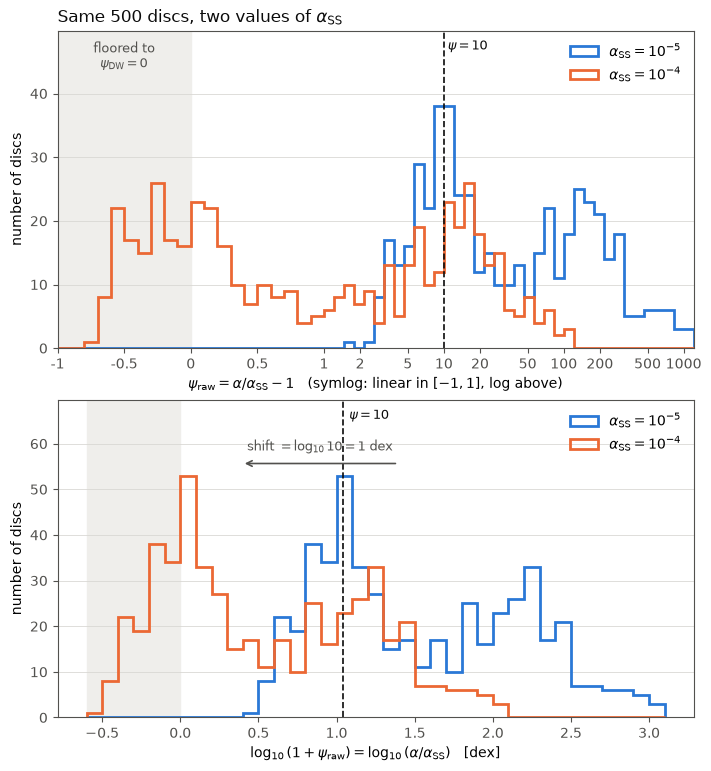

In [9]:
# =====================================================================================
# 4c. psi_raw of the SAME 500 discs for alpha_SS = 1e-5 (repo CSV) vs 1e-4 (companion CSV)
#     (Hof, 2026-10-29; needs cell 4: pop_ms, POP_CSV_MS)
# =====================================================================================
# 1 + psi_raw = alpha / alpha_SS  [dimensionless]   (alpha = Malanga's alpha_DW = our TOTAL alpha;
#   Tabone et al. 2022, Eqs. 12-13). Same alpha for both files -> (1 + psi_1e-4) = (1 + psi_1e-5) / 10.
# Top panel:    psi_raw on the same symlog axis as cell 4b (shape is distorted near psi ~ 1, and psi < 0 appears)
# Bottom panel: log10(1 + psi_raw) = log10(alpha / alpha_SS): a pure 1-dex shift, same shape
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

POP_CSV_MS_1E4 = POP_CSV_MS.replace("_seed1.csv", "_seed1_aSS1e-4.csv")   # companion file, alpha_SS = 1e-4
pop_ms_1e4 = pd.read_csv(POP_CSV_MS_1E4).set_index("id")

# ---- sanity checks: same discs, only alpha_SS differs ----
for col in ["Mstar_Msun", "M0_Msun", "R0_au", "alpha_DW_Malanga"]:
    assert np.allclose(pop_ms[col], pop_ms_1e4[col], rtol=0, atol=0), f"{col} differs between the two CSVs"
POPS_C = {  # label -> (population table, alpha_SS, colour); colour follows the alpha_SS value in this cell
    r"$\alpha_{\rm SS} = 10^{-5}$": (pop_ms,     float(pop_ms.alpha_SS.iloc[0]),     "#2a78d6"),   # blue (slot 1)
    r"$\alpha_{\rm SS} = 10^{-4}$": (pop_ms_1e4, float(pop_ms_1e4.alpha_SS.iloc[0]), "#eb6834"),   # orange (slot 2)
}
assert [a for _, a, _ in POPS_C.values()] == [1e-5, 1e-4], "unexpected alpha_SS values in the two CSVs"
psi5 = pop_ms["psi_raw"].to_numpy()            # dimensionless, alpha_SS = 1e-5
psi4 = pop_ms_1e4["psi_raw"].to_numpy()        # dimensionless, alpha_SS = 1e-4
# exact relation, up to the 4-significant-figure rounding of psi_raw in the CSVs
rel_err = np.abs((1 + psi4) - (1 + psi5) / 10) / (1 + psi4)
print(f"(1 + psi_1e-4) = (1 + psi_1e-5) / 10 holds to max relative error {rel_err.max():.1e} (4 sf rounding)")

# ---- counts per population ----
PSI_WINDY_C = 10.0   # dimensionless; same ARBITRARY windy threshold as cell 4b (PSI_WINDY)
n_c = len(psi5)
print(f"\n{'':22s} {'psi<0 (floored)':>16s} {'0<=psi<10':>11s} {'psi>=10':>9s} {'median psi_raw':>15s} {'median psi_DW':>14s}")
for label, (pop, aSS, _) in POPS_C.items():
    p = pop["psi_raw"].to_numpy()
    print(f"alpha_SS = {aSS:<11g} {int((p < 0).sum()):16d} {int(((p >= 0) & (p < PSI_WINDY_C)).sum()):11d} "
          f"{int((p >= PSI_WINDY_C).sum()):9d} {np.median(p):15.3g} {np.median(pop['psi_DW']):14.3g}")
print(f"Discs with psi_1e-5 < 9 (-> psi_1e-4 < 0, floored): {int((psi5 < 9).sum())}; "
      f"M* of the floored discs at 1e-4: {pop_ms_1e4.Mstar_Msun[psi4 < 0].min():.3g}-"
      f"{pop_ms_1e4.Mstar_Msun[psi4 < 0].max():.3g} Msun" if (psi4 < 0).any() else "no floored discs at 1e-4")
print(f"lambda < 1.5 flagged: {int(pop_ms.flag_lambda_lt_1p5.sum())} (1e-5) vs {int(pop_ms_1e4.flag_lambda_lt_1p5.sum())} (1e-4)")

# ---- figure ----
INK_C, MUTED_C, GRID_C, FLOOR_C = "#0b0b0b", "#52514e", "#d9d8d4", "#efeeeb"   # text / axes / grid / psi<0 band
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(7.0, 7.6), constrained_layout=True)
for ax in (ax1, ax2):
    ax.grid(True, axis="y", color=GRID_C, lw=0.6); ax.set_axisbelow(True)
    for s in ax.spines.values(): s.set_color(MUTED_C)
    ax.tick_params(colors=MUTED_C)

# (top) psi_raw, symlog: linear in [-1, 1], log above; bins as cell 4b (0.1 wide, then ~12 per decade)
top_c = 10 ** (np.ceil(np.log10(max(psi5.max(), psi4.max())) * 12) / 12)
edges_c = np.concatenate([np.linspace(-1.0, 1.0, 21),
                          np.logspace(0.0, np.log10(top_c), int(round(np.log10(top_c) * 12)) + 1)[1:]])
ax1.axvspan(-1.0, 0.0, color=FLOOR_C, zorder=0)                                    # psi < 0: floored region
ax1.text(-0.5, 0.97, "floored to\n" + r"$\psi_{\rm DW} = 0$", transform=ax1.get_xaxis_transform(),
         ha="center", va="top", color=MUTED_C, fontsize=9)
for label, (pop, aSS, col) in POPS_C.items():
    ax1.hist(pop["psi_raw"], bins=edges_c, histtype="step", lw=2.0, color=col, label=label)
ax1.set_xscale("symlog", linthresh=1.0, linscale=1.0)
ax1.set_xticks([t for t in [-1, -0.5, 0, 0.5, 1, 2, 5, 10, 20, 50, 100, 200, 500, 1000] if t <= edges_c[-1]])
ax1.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
ax1.set_xlim(edges_c[0], edges_c[-1])
ax1.axvline(PSI_WINDY_C, color=INK_C, lw=1.2, ls="--")
ax1.text(PSI_WINDY_C * 1.08, 0.97, rf"$\psi = {PSI_WINDY_C:g}$", transform=ax1.get_xaxis_transform(),
         va="top", ha="left", color=INK_C, fontsize=9)
ax1.set_ylim(0, ax1.get_ylim()[1] * 1.25)                                          # headroom for labels
ax1.set_xlabel(r"$\psi_{\rm raw} = \alpha/\alpha_{\rm SS} - 1$   (symlog: linear in $[-1, 1]$, log above)")
ax1.set_ylabel("number of discs")
ax1.set_title(rf"Same {n_c} discs, two values of $\alpha_{{\rm SS}}$", loc="left", color=INK_C)
ax1.legend(frameon=False, loc="upper right")

# (bottom) log10(1 + psi_raw) = log10(alpha / alpha_SS): 0.1 dex bins, identical shape shifted by 1 dex
x5, x4 = np.log10(1 + psi5), np.log10(1 + psi4)                                   # dex
edges_x = np.arange(np.floor(x4.min() * 10) / 10, np.ceil(x5.max() * 10) / 10 + 0.1, 0.1)
for (label, (pop, aSS, col)), x in zip(POPS_C.items(), (x5, x4)):
    ax2.hist(x, bins=edges_x, histtype="step", lw=2.0, color=col, label=label)
ax2.axvspan(edges_x[0], 0.0, color=FLOOR_C, zorder=0)                              # alpha < alpha_SS: floored
ax2.axvline(np.log10(1 + PSI_WINDY_C), color=INK_C, lw=1.2, ls="--")               # psi = 10 <-> log10(11)
ax2.text(np.log10(1 + PSI_WINDY_C) + 0.04, 0.97, rf"$\psi = {PSI_WINDY_C:g}$", transform=ax2.get_xaxis_transform(),
         va="top", ha="left", color=INK_C, fontsize=9)
ax2.set_ylim(0, ax2.get_ylim()[1] * 1.25)
ax2.annotate("", xy=(np.median(x4), ax2.get_ylim()[1] * 0.80), xytext=(np.median(x5), ax2.get_ylim()[1] * 0.80),
             arrowprops=dict(arrowstyle="->", color=MUTED_C, lw=1.2))              # median-to-median arrow
ax2.text((np.median(x4) + np.median(x5)) / 2, ax2.get_ylim()[1] * 0.83,
         rf"shift $= \log_{{10}} 10 = 1$ dex", ha="center", va="bottom", color=MUTED_C, fontsize=9)
ax2.set_xlabel(r"$\log_{10}(1+\psi_{\rm raw}) = \log_{10}(\alpha/\alpha_{\rm SS})$   [dex]")
ax2.set_ylabel("number of discs")
ax2.legend(frameon=False, loc="upper right")
plt.show()

## 5. Pilot 3: did the runs finish, and do the discs evolve sensibly?
*(Hof, 2026-10-30)* Diagnosis of the 23-disc pilot of **population v3** ($\alpha_{\rm SS} = 10^{-5}$; $M_\star$ in 0.1–1.5 $M_\odot$; $r_{\rm max} = \min(20\,R_0, 1000$ au$)$; $r_{\rm min} = 0.1$ au $(R_\star/3.079\,R_\odot)^{12/7}$ in [0.03, 0.1] au). The cell does not need cells 1–4. It reads `/scratch/.../malanga_mstar_aSS1e-5_v3` when run on Nibi, otherwise the local rsync copy.

**Figures**
1. **Completion:** runtime and last snapshot vs $R_0$, by run status.
2. **Bulk evolution:** $M(t)$, $\dot M_\star(t)$, $M/\dot M_\star(t)$ and the $\dot M_\star$–$M$ tracks, with Malanga's dispersal thresholds (p. 5) and isochrone (Fig. 4b). One line per disc, coloured by $1+\psi = \alpha/\alpha_{\rm SS}$ (Tabone et al. 2022, Eqs. 12–13).
3. **Mass budget and wind:** where $M(0)$ went by the last snapshot; $f_M = M_{\rm lost}/M_{\rm acc}$ against the target $(R_0/r_{\rm min})^\xi - 1$ (Tabone Eqs. 22/31; the lever arm follows from Balogh et al. 2026, Eq. 16); time to lose half the mass, code vs analytic.
4. **Grid edges:** does the disc run into the new $r_{\rm max} = 20\,R_0$? Compares $R_{50}$ growth with the analytic $r_c(t)$.
5. **Radial profiles:** $\Sigma_{\rm G}(R)$ and $T(R)$ at several times, for the lowest-$\psi$, median-$\psi$, highest-$\psi$ and most compact discs.

**Reading the results**
- $M_{\rm lost}$ is not purely wind. The outer boundary is zero-torque, so gas reaching $r_{\rm max}$ leaves the grid and is counted as lost. Figure 4 and the `f_outer` checks show whether that matters for a given disc.
- The analytic $t_{1/2}$ and $r_c(t)$ use the CSV's Malanga-equivalent $t_{\rm acc,0}$, so code/analytic $\neq 1$ is **expected**. The code's $T(R_0)$ is 2–5× lower than Malanga's Eq. 3 (longer timescale), while the inner disc sits at $T_{\rm max} = 1500$ K (the Step 3 flag: initial $\dot M \sim 2.2\times$ analytic at 1 $M_\odot$).
- $R_{50}$ also grows when a disc empties from the inside out, not only when it spreads, so a large value in Figure 4 does not by itself mean viscous spreading.
- Discs with very little mass accreted so far have an unreliable $f_M$, a ratio of two small numbers.

The cell ends with one-line checks (`FLAG` = look at this disc; `info` = reported for context) and a table with one row per disc.

Data: /scratch/imontesd/output/DiscEvolution/popsynth/malanga_mstar_aSS1e-5_v3
Population: /scratch/imontesd/output/DiscEvolution/popsynth/malanga_mstar_aSS1e-5_v3/malanga_mstar_draws_Hof_N500_seed1.csv

--- Completion ---
status
done    23
runtime [h]: median 0.47, max 7.46 (job limit 24 h; killed runs have no runtime)
Rough full-population cost: 240 CPU-h, wall ~7.5 h on 150 slots (from 23 finished discs; R0 outside their range uses the nearest disc)


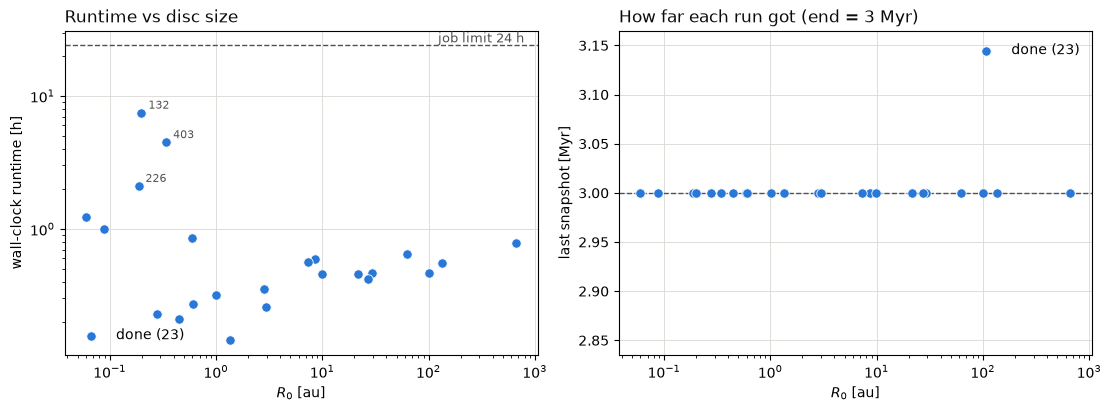

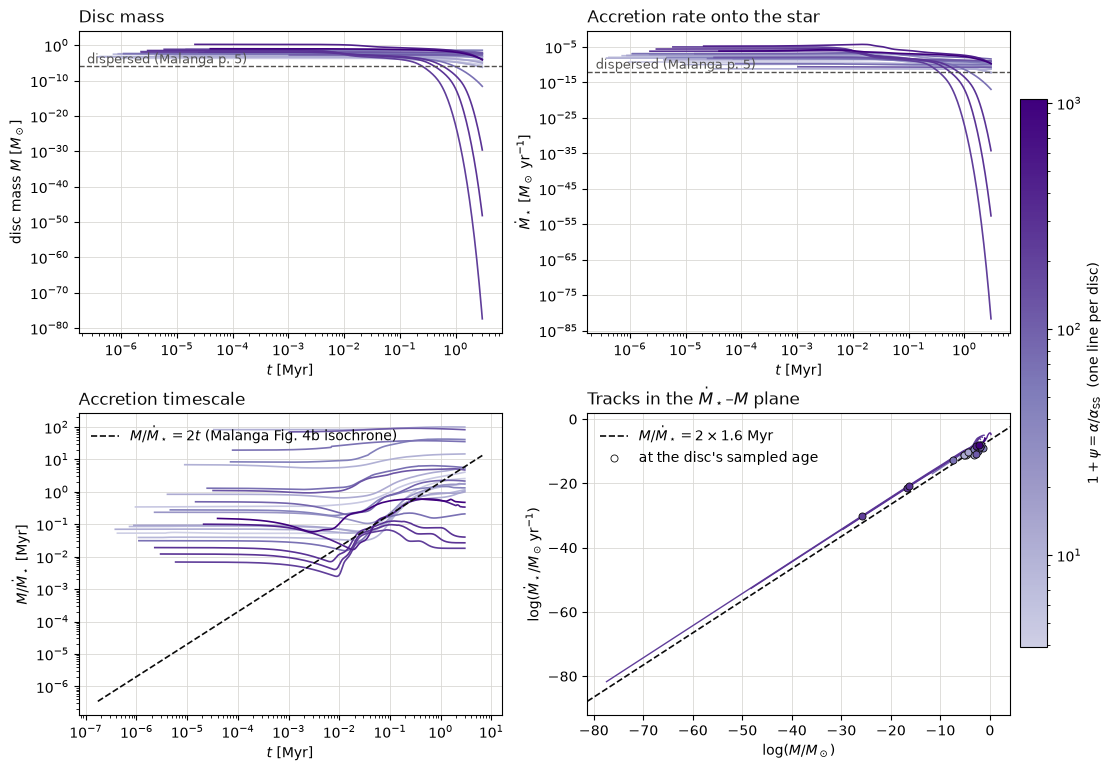

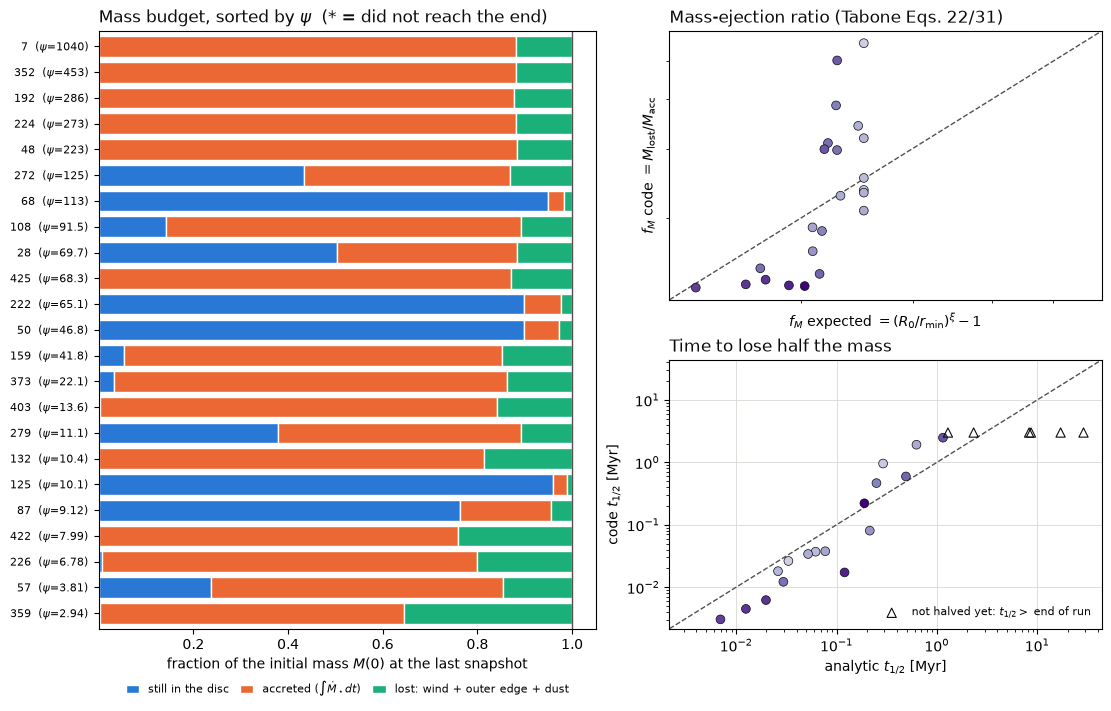

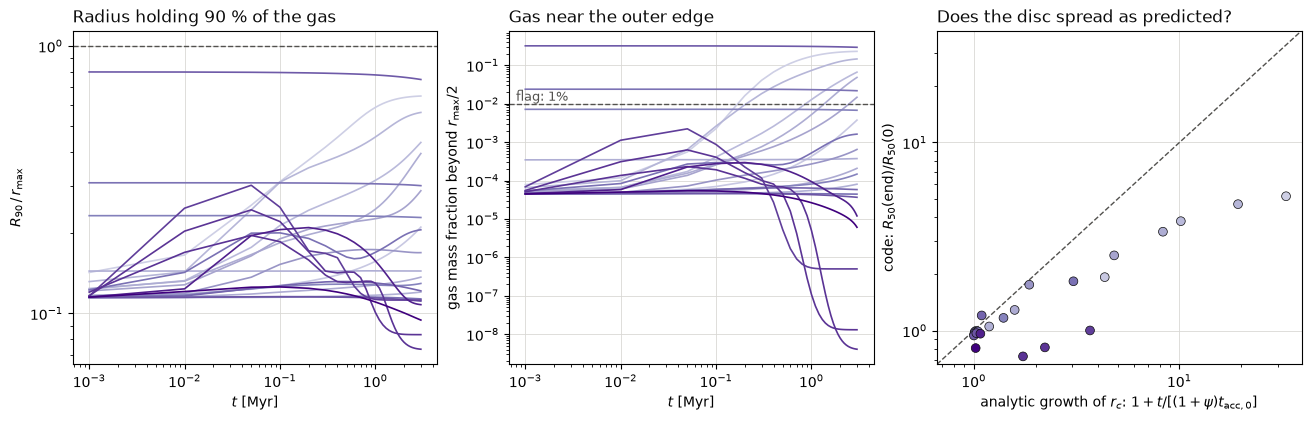

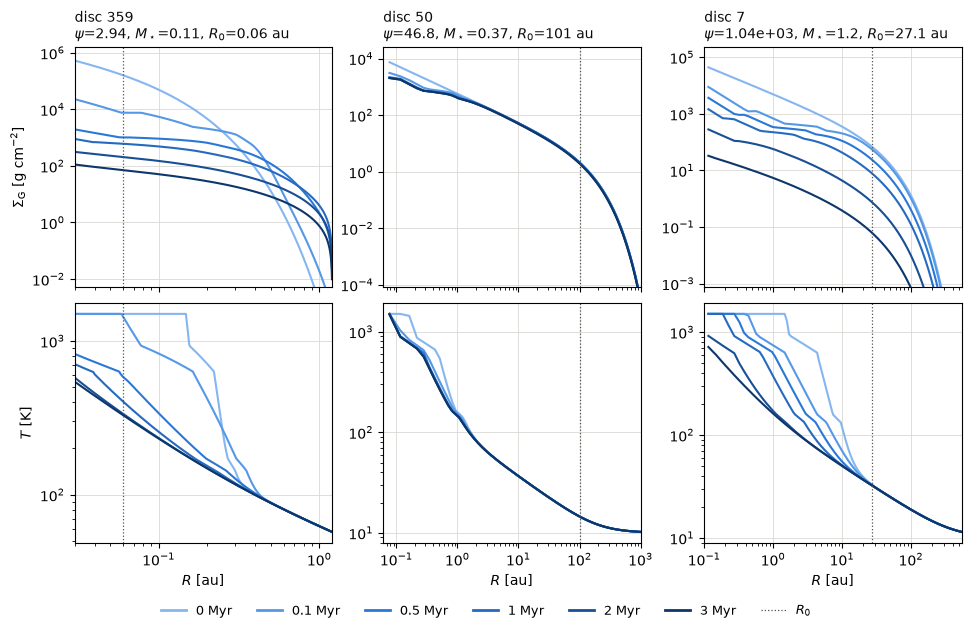

--- Checks ---
[ok  ] discs not finished (no file / unreadable / not run / crashed / killed): 0
[ok  ] M*, R*, r_min or r_max in the .h5 differ from the population CSV: 0
[ok  ] M(0) in the .h5 differs from the CSV M0 by > 1 %: 0
[ok  ] NaN or inf in Sigma_G, T, M or Mdot: 0
[ok  ] mass increases above M(0) by > 0.1 %: 0
[ok  ] Mdot_* < 0 after 10 kyr (net outflow at the inner cell): 0
[ok  ] T above the 1500 K cap of the EOS by > 1 %: 0
[ok  ] accreted more than the disc lost (f_lost < -1 %: Mdot_* diagnostic overshoots): 0
[FLAG] > 1% of the gas beyond r_max/2 at the START (R0 cap at 1000 au): 2  ids [222, 68]
[FLAG] > 1% of the gas beyond r_max/2 at some time (M_lost contaminated by the outer edge): 7  ids [359, 226, 422, 132, 403, 222, 68]
[info] f_M,code off by more than x2 from (R0/r_min)^xi - 1 (Tabone Eqs. 22/31): 2  ids [359, 68]
[info] t_1/2 code differs from analytic by > x2 (expected: see the Step 3 flag / t_acc,0 note in the header): 10  ids [57, 279, 403, 373, 425, 272, 4

,id,status,Mstar,R0_au,M0,M0/Mstar,psi,rmin_au,rmax_au,t_last_Myr,...,GI_flag,f_disc,f_acc,f_lost,f_M_code,f_M_expected,t_half_code,t_half_analytic,R90_rmax_end,f_outer_max
0,359,done,0.1072,0.0600,0.0007,0.0064,2.938,0.0300,1.200,3.0,...,False,0.0037,0.6404,0.3559,0.5557,0.2512,0.0263,0.0331,0.6492,0.2307
1,57,done,0.1000,0.5962,0.0002,0.0019,3.805,0.0300,11.920,3.0,...,False,0.2379,0.6168,0.1453,0.2355,0.2512,0.9564,0.2906,0.2102,0.0037
2,226,done,0.1349,0.1868,0.0028,0.0209,6.778,0.0300,3.736,3.0,...,False,0.0063,0.7933,0.2004,0.2526,0.2512,0.0370,0.0618,0.4355,0.0664
3,422,done,0.1514,0.0884,0.0040,0.0266,7.985,0.0300,1.767,3.0,...,False,0.0001,0.7582,0.2417,0.3188,0.2512,0.0180,0.0261,0.5637,0.1463
4,87,done,0.1514,8.5820,0.0008,0.0051,9.121,0.0300,171.600,3.0,...,False,0.7637,0.1918,0.0445,0.2318,0.2512,NaN,2.3207,0.1202,0.0001
5,125,done,0.1862,62.8400,0.0005,0.0029,10.140,0.0345,1000.000,3.0,...,False,0.9602,0.0296,0.0101,0.3426,0.2461,NaN,17.0619,0.1440,0.0004
6,132,done,0.1862,0.1991,0.0005,0.0027,10.380,0.0345,3.982,3.0,...,False,0.0012,0.8136,0.1852,0.2277,0.2307,0.0340,0.0520,0.3959,0.0484
7,279,done,0.1479,2.8160,0.0018,0.0125,11.050,0.0300,56.320,3.0,...,False,0.3784,0.5143,0.1073,0.2086,0.2512,1.9145,0.6251,0.1366,0.0002
8,403,done,0.2344,0.3401,0.0037,0.0159,13.640,0.0437,6.802,3.0,...,False,0.0022,0.8390,0.1587,0.1892,0.2084,0.0376,0.0771,0.2874,0.0147
9,373,done,0.2884,1.3580,0.0168,0.0584,22.110,0.0541,27.160,3.0,...,False,0.0328,0.8305,0.1367,0.1645,0.2086,0.0804,0.2141,0.1687,0.0006


In [1]:
# =====================================================================================
# 5. Pilot 3 (population v3): did the runs finish, and do the discs evolve sensibly?
#    (Hof, 2026-10-30) SELF-CONTAINED: does not need cells 1-4. Variables end in _p3.
#    Reads only; writes nothing to disk.
# =====================================================================================
# Population v3 (sample_malanga_mstar_Hof.py, alpha_SS = 1e-5): M* in 0.1-1.5 Msun, r_max = min(20 R0, 1000 au),
# r_min = 0.1 au (R*/3.079 Rsun)^(12/7) kept in [0.03, 0.1] au. 23 discs, run_popsynth_malanga_Hof.sh.
#
# HDF5 units (CLAUDE.md): t [yr], time_snap [Myr], disk_Mass [g], disk_Mdot_star [Msun/yr],
#   Sigma_G [g/cm^2], T [K], R [AU]. M0 and M(t) below are in Msun, after dividing by Msun.
#
# Run status (from HDF5 attrs). run_model_Hof.py writes complete, run_start and run_end in a `finally:`
# block, so they ALSO appear after a crash, and there is NO ETA-based abort (removed; the config key
# eta_abort_hours is ignored). So:
#   done      complete = True and the last snapshot reached P3_T_END_MYR
#   crashed   complete = True but the last snapshot is earlier (Python exception; see the .err log)
#   killed    no complete attr: the process died without reaching `finally` (Slurm time limit, node, memory)
#   not run   attr Mdot_out_of_range = True (the initial Mdot was outside the valid range)
#   no file / unreadable
#
# Mass budget of one disc at time t [all in Msun]:
#   M_acc(t)  = int_0^t Mdot_*(t') dt'                accreted, measured at the innermost cell
#   M_lost(t) = M(0) - M(t) - M_acc(t)                wind + anything else that left
#   f_M,code  = M_lost / M_acc                        vs f_M_grid_expected = (R0/r_min)^xi - 1 (Tabone et al. 2022, Eqs. 22/31)
# M_lost is NOT purely wind. It also contains (i) gas leaving through the OUTER edge: the gas solver uses
# boundary = "Zero" (zero torque; run_model_Hof.build_transport), so gas that reaches r_max leaves the grid;
# (ii) dust drifting through the inner edge faster than the gas (at most ~d2g = 1 % of M0); (iii) the early
# Mdot_* error (the diagnostic does not close the budget for the first few kyr; treat early Mdot with care).
# Check (i) directly with f_outer and R90/r_max below.
#
# Analytic comparison, hybrid self-similar solution (Tabone et al. 2022; same formula as TaboneSolution in
# DiscEvolution/viscous_evolution.py), with T(t) = 1 + t / ((1 + psi) t_acc,0):
#   r_c(t) = R0 T(t)        M(t) = M0 T(t)^(-(psi + 1 + 2 xi) / 2)
#   -> time to lose half the mass: t_half = (1 + psi) t_acc,0 (2^(2 / (psi + 1 + 2 xi)) - 1)  [Myr]
# M(t) comes from integrating that Sigma(R, t) over R; its exponent matches the (psi + 1 + 2 xi) factor of
# Tabone Eq. 42. t_acc,0 is the CSV's MALANGA-EQUIVALENT value (H/r from Malanga Eq. 3), not the code's. The
# code's temperature differs: T(R0) is 2-5x lower, which lengthens t_acc,0, while the inner disc sits at
# T_max = 1500 K (the "Step 3 flag": initial Mdot ~2.2x analytic at 1 Msun). So code/analytic != 1 is EXPECTED.
import os, re, glob
from datetime import datetime
import numpy as np
import pandas as pd
import h5py
import matplotlib.pyplot as plt
from matplotlib import colors as mcolors
from matplotlib.lines import Line2D
from matplotlib.ticker import NullFormatter
from DiscEvolution.constants import Msun                                 # g

# ---- settings ------------------------------------------------------------------------
# First folder that holds .h5 files is used: Nibi scratch when run on Nibi, else the local rsync copy.
P3_DIR_CANDIDATES = ["/scratch/imontesd/output/DiscEvolution/popsynth/malanga_mstar_aSS1e-5_v3",
                     "/home/imontesd/output/DiscEvolution/popsynth/malanga_mstar_aSS1e-5_v3"]
P3_IDS = [425, 224, 226, 359, 422, 373, 403, 57, 192, 159, 108, 272,   # the discs submitted for pilot 3
          50, 222, 68, 125, 87, 132, 7, 28, 48, 352, 279]
P3_T_END_MYR = 3.0       # Myr, last snapshot of DiscConfig_Hof_malanga_mstar.json
P3_T_RTOL = 1e-3         # dimensionless, tolerance for "reached the end"
P3_JOB_LIMIT_H = 24.0    # h, --time of run_popsynth_malanga_Hof.sh (1-00:00:00)
P3_NPROC_FULL = 150      # runs at once in run_popsynth_malanga_full_Hof.sh (for the wall-time estimate)
M_DISPERSED = 1e-6       # Msun,     Malanga et al. (2026) p. 5: below this a disc counts as dispersed
MDOT_DISPERSED = 1e-12   # Msun/yr,  same
LUPUS_AGE_MYR = 1.6      # Myr, Malanga Table 2 mean age; isochrone M/Mdot = 2 t in the track panel
F_OUTER_FLAG = 0.01      # dimensionless; flag a disc with > 1 % of its gas beyond r_max / 2 at any snapshot
M0_MSTAR_FLAG = 0.1      # dimensionless; M0/M* above this is a massive disc (worth a look; see also the GI flag)
PROFILE_TIMES_MYR = [0.0, 0.1, 0.5, 1.0, 2.0, 3.0]    # Myr, nearest snapshots drawn in the profile figure
N_PLOT = 400             # points per time series on plots (series have one point per 5 steps)

INK, MUTED, GRID = "#0b0b0b", "#52514e", "#d9d8d4"    # text / reference lines / grid (as in cells 2b, 4b)
C1, C2, C3 = "#2a78d6", "#eb6834", "#1baf7a"          # categorical slots 1-3 (blue, orange, aqua)
STATUS_STYLE = {"done": ("o", C1), "crashed": ("s", C2), "killed": ("X", C3)}   # marker + colour per status
RAMP_T = ["#86b6ef", "#5598e7", "#2a78d6", "#256abf", "#184f95", "#0d366b"]     # early (light) -> late (dark)

# ---- find the data ---------------------------------------------------------------------
P3_DIR = next((d for d in P3_DIR_CANDIDATES if glob.glob(os.path.join(d, "hof_malanga_w0_*.h5"))), None)
if P3_DIR is None:
    raise FileNotFoundError("No pilot 3 .h5 files in:\n  " + "\n  ".join(P3_DIR_CANDIDATES) + "\nCopy them from Nibi, e.g.\n"
                            "  rsync -avz nibi:/scratch/imontesd/output/DiscEvolution/popsynth/malanga_mstar_aSS1e-5_v3/ "
                            "/home/imontesd/output/DiscEvolution/popsynth/malanga_mstar_aSS1e-5_v3/")
# Layout written by the launcher: <OUTPUT_ROOT>/popsynth/<folder> and <OUTPUT_ROOT>/logs/malanga-comparison/<log folder>
P3_LOGS = os.path.normpath(os.path.join(P3_DIR, "..", "..", "logs", "malanga-comparison", "mstar_aSS1e-5_v3", "run_logs"))

# The population CSV the launcher copied next to the runs; fall back on the repo copy (same file if unchanged)
_csvs = glob.glob(os.path.join(P3_DIR, "malanga_mstar_draws_Hof_*.csv"))
_repo_csv = os.path.abspath(os.path.join(os.getcwd(), "..", "config", "malanga", "malanga_mstar_draws_Hof_N500_seed1.csv"))
P3_CSV = _csvs[0] if len(_csvs) == 1 else _repo_csv
pop_p3 = pd.read_csv(P3_CSV).set_index("id")
print(f"Data: {P3_DIR}\nPopulation: {P3_CSV}")


# ---- read every run --------------------------------------------------------------------
def read_run_p3(path):
    """Everything needed from one .h5 file [units in the header]; raises OSError if it cannot be opened."""
    with h5py.File(path, "r") as h:
        a = h.attrs
        r = {"complete": bool(a.get("complete", False)), "not_run": bool(a.get("Mdot_out_of_range", False)),
             "runtime_h": np.nan, "GI_flag": bool(a.get("GI_flag", False)),
             "Q_min": float(a.get("Q_toomre_min", np.nan)),                    # dimensionless, Balogh et al. 2026 Eq. 48
             "attr_Mstar": float(a.get("Mstar_Msun", np.nan)), "attr_Rstar": float(a.get("Rstar_Rsun", np.nan)),   # Msun, Rsun
             "attr_rmin": float(a.get("grid_rmin_au", np.nan)), "attr_rmax": float(a.get("grid_rmax_au", np.nan))}  # AU
        if "run_start" in a and "run_end" in a:
            r["runtime_h"] = (datetime.fromisoformat(str(a["run_end"]))
                              - datetime.fromisoformat(str(a["run_start"]))).total_seconds() / 3600     # h
        empty = np.empty(0)
        r["t"] = h["t"][:] if "t" in h else empty                               # yr
        r["M"] = h["disk_Mass"][:] / Msun if "disk_Mass" in h else empty        # Msun
        r["Mdot"] = h["disk_Mdot_star"][:] if "disk_Mdot_star" in h else empty  # Msun/yr
        r["t_snap"] = h["time_snap"][:] if "time_snap" in h else empty          # Myr
        r["R"] = h["R"][:] if "R" in h else empty                               # AU
        n_snap = len(r["t_snap"])
        r["Sigma_G"] = h["Sigma_G"][:n_snap] if "Sigma_G" in h else empty       # g/cm^2, one row per snapshot
        r["T"] = h["T"][:n_snap] if "T" in h else empty                         # K, one row per snapshot
    # a killed run can leave series of slightly different lengths: keep the common part
    n = min(len(r["t"]), len(r["M"]), len(r["Mdot"]))
    r["t"], r["M"], r["Mdot"] = r["t"][:n], r["M"][:n], r["Mdot"][:n]
    return r


def enclosed_radius_p3(R, Sigma, frac):
    """Radius [AU] enclosing `frac` of the gas mass of one snapshot (cell mass 2 pi R Sigma dR; R non-uniform)."""
    m = R * Sigma * np.gradient(R)                                             # arbitrary units; only ratios are used
    cum = np.cumsum(m)
    return float(np.interp(frac, cum / cum[-1], R))


def t_half_code_p3(t, M):
    """First time [Myr] the disc has lost half of M[0]; NaN if it never does. t in yr, M in Msun."""
    below = np.flatnonzero(M <= 0.5 * M[0])
    if below.size == 0:
        return np.nan
    i = below[0]
    return float(np.interp(0.5 * M[0], [M[i], M[i - 1]], [t[i], t[i - 1]])) / 1e6 if i > 0 else float(t[0]) / 1e6


runs_p3, rows_p3 = {}, []
for disc_id in P3_IDS:
    d = pop_p3.loc[disc_id]
    row = {"id": disc_id, "status": "no file", "Mstar": d.Mstar_Msun, "R0_au": d.R0_au, "M0": d.M0_Msun,
           "M0/Mstar": d.M0_Msun / d.Mstar_Msun, "psi": d.psi_DW, "rmin_au": d.rmin_au, "rmax_au": d.rmax_au}
    found = glob.glob(os.path.join(P3_DIR, f"hof_malanga_w0_{disc_id:04d}_*.h5"))
    if found:
        try:
            r = read_run_p3(found[0])
        except OSError as err:                                                 # e.g. truncated by a kill
            row["status"] = "unreadable"
            print(f"  disc {disc_id}: cannot open {os.path.basename(found[0])}: {err}")
            r = None
        if r is not None:
            t_last = float(r["t_snap"][-1]) if len(r["t_snap"]) else np.nan    # Myr
            reached = bool(t_last >= P3_T_END_MYR * (1 - P3_T_RTOL))
            row["status"] = ("not run" if r["not_run"] else "done" if (r["complete"] and reached)
                             else "crashed" if r["complete"] else "killed")
            row.update(t_last_Myr=t_last, runtime_h=r["runtime_h"], n_steps=5 * len(r["t"]), GI_flag=r["GI_flag"], Q_min=r["Q_min"])
            if len(r["t"]) >= 2 and len(r["t_snap"]) >= 1:
                t, M, Mdot = r["t"], r["M"], r["Mdot"]
                M_acc = np.trapezoid(Mdot, t)                                  # Msun
                M_lost = M[0] - M[-1] - M_acc                                  # Msun
                # gas radii per snapshot [AU]; f_outer = gas mass fraction beyond r_max / 2 [dimensionless]
                R, Sig = r["R"], r["Sigma_G"]
                r["R50"] = np.array([enclosed_radius_p3(R, s, 0.5) for s in Sig])
                r["R90"] = np.array([enclosed_radius_p3(R, s, 0.9) for s in Sig])
                m_cell = R * Sig * np.gradient(R)                              # rows: snapshots
                r["f_outer"] = m_cell[:, R > 0.5 * d.rmax_au].sum(axis=1) / m_cell.sum(axis=1)
                T_end = 1 + t_last / ((1 + d.psi_DW) * d.t_acc0_Myr)           # dimensionless, Tabone T(t) at t_last
                row.update(M_end=M[-1], f_disc=M[-1] / M[0], f_acc=M_acc / M[0], f_lost=M_lost / M[0],
                           f_M_code=M_lost / M_acc if M_acc > 0 else np.nan, f_M_expected=d.f_M_grid_expected,
                           Mdot_end=Mdot[-1],
                           t_half_code=t_half_code_p3(t, M),                   # Myr
                           t_half_analytic=(1 + d.psi_DW) * d.t_acc0_Myr
                                           * (2 ** (2 / (d.psi_DW + 1 + 2 * d.xi)) - 1),   # Myr, formula in the header
                           R50_growth=r["R50"][-1] / r["R50"][0], R50_growth_analytic=T_end,   # dimensionless
                           R90_rmax_end=r["R90"][-1] / d.rmax_au,              # dimensionless
                           f_outer_0=float(r["f_outer"][0]), f_outer_max=float(np.max(r["f_outer"])),
                           Mdot0_ratio=Mdot[0] / d.Mdot0_est_Msun_yr,          # code / analytic (Tabone Eq. 42) at t = 0
                           T_max_K=float(np.nanmax(r["T"])),
                           n_nonfinite=int(np.sum(~np.isfinite(Sig)) + np.sum(~np.isfinite(r["T"]))
                                           + np.sum(~np.isfinite(M)) + np.sum(~np.isfinite(Mdot))),
                           # Mdot < 0 (net outflow at the inner cell), ignoring the first 10 kyr (known early transient)
                           n_Mdot_neg=int(np.sum((Mdot < 0) & (t > 1e4))),
                           M_rise=float(np.max(M) / M[0] - 1))                 # dimensionless; > 0 means mass appeared
                # at the disc's sampled age (NaN if the run did not get there)
                t_age = d.t_age_Myr * 1e6                                      # yr
                if t[-1] >= t_age:
                    row.update(M_age=float(np.interp(t_age, t, M)), Mdot_age=float(np.interp(t_age, t, Mdot)))
                runs_p3[disc_id] = r
    rows_p3.append(row)
p3 = pd.DataFrame(rows_p3).sort_values("psi").reset_index(drop=True)
for col in ["t_last_Myr", "runtime_h", "M_age", "Mdot_age", "f_outer_max", "t_half_code"]:   # always present, even with no data
    if col not in p3:
        p3[col] = np.nan
ok_p3 = p3[p3.id.isin(runs_p3)]                 # discs with usable series, sorted by psi

# ---- 1. completion ----------------------------------------------------------------------
print("\n--- Completion ---")
print(p3.status.value_counts().to_string())
print(f"runtime [h]: median {p3.runtime_h.median():.2f}, max {p3.runtime_h.max():.2f} "
      f"(job limit {P3_JOB_LIMIT_H:g} h; killed runs have no runtime)")
_nofile = p3.id[p3.status == "no file"].tolist()
if _nofile:
    print(f"  no .h5 file yet ({len(_nofile)} discs): {_nofile}")
for _, row in p3[~p3.status.isin(["done", "no file"])].iterrows():    # what happened to the others: end of their logs
    rn = f"hof_malanga_w0_{row.id:04d}"
    tail = ""
    for ext in (".err", ".out"):
        p = os.path.join(P3_LOGS, rn + ext)
        if os.path.isfile(p):
            with open(p, errors="replace") as f:
                lines = [l.strip() for l in f.read().replace("\r", "\n").split("\n") if l.strip()]
            if ext == ".err" and lines:
                tail += f"\n      .err: {lines[-1][:150]}"
            times = [l for l in lines if l.startswith("Time:")] if ext == ".out" else []
            if times:
                tail += f"\n      .out: {times[-1][:60]}"
    print(f"  disc {row.id}: {row.status}, last snapshot {row.t_last_Myr:.3g} Myr, R0 = {row.R0_au:.3g} au, psi = {row.psi:.4g}"
          + (tail or "\n      (no log found in " + P3_LOGS + ")"))

# Rough cost of the full population: runtime interpolated in log R0 (runtime is set mostly by R0) over all CSV discs
dn = p3[(p3.status == "done") & np.isfinite(p3.runtime_h)].sort_values("R0_au")
if len(dn) >= 2:
    est_h = 10 ** np.interp(np.log10(pop_p3.R0_au), np.log10(dn.R0_au), np.log10(dn.runtime_h.clip(lower=1e-3)))
    print(f"Rough full-population cost: {est_h.sum():.0f} CPU-h, wall ~{max(est_h.sum() / P3_NPROC_FULL, est_h.max()):.1f} h on "
          f"{P3_NPROC_FULL} slots (from {len(dn)} finished discs; R0 outside their range uses the nearest disc)")

fig, axs = plt.subplots(1, 2, figsize=(11.0, 4.0), constrained_layout=True)
for ax, ycol, ylab in [(axs[0], "runtime_h", "wall-clock runtime [h]"), (axs[1], "t_last_Myr", "last snapshot [Myr]")]:
    for status, (marker, col) in STATUS_STYLE.items():
        s = p3[(p3.status == status) & np.isfinite(p3[ycol])]
        if len(s):
            ax.scatter(s.R0_au, s[ycol], marker=marker, s=46, color=col, edgecolor="white", linewidths=0.6, zorder=3,
                       label=f"{status} ({len(s)})")
    ax.set_xscale("log"); ax.set_xlabel(r"$R_0$ [au]"); ax.set_ylabel(ylab)
    ax.grid(True, color=GRID, lw=0.6); ax.set_axisbelow(True)
    if ax.has_data():
        ax.legend(frameon=False)
axs[0].set_yscale("log")
axs[0].axhline(P3_JOB_LIMIT_H, color=MUTED, lw=1.0, ls="--")
axs[0].text(0.98, P3_JOB_LIMIT_H, f"job limit {P3_JOB_LIMIT_H:g} h ", color=MUTED, fontsize=9, ha="right", va="bottom",
            transform=axs[0].get_yaxis_transform())
for _, row in dn.nlargest(min(3, len(dn)), "runtime_h").iterrows():           # name the slowest finished discs
    axs[0].annotate(f"{row.id}", (row.R0_au, row.runtime_h), xytext=(5, 3), textcoords="offset points", fontsize=8, color=MUTED)
axs[1].axhline(P3_T_END_MYR, color=MUTED, lw=1.0, ls="--")
axs[0].set_title("Runtime vs disc size", loc="left", color=INK)
axs[1].set_title(f"How far each run got (end = {P3_T_END_MYR:g} Myr)", loc="left", color=INK)
plt.show()


# ---- 2. bulk evolution, one line per disc, coloured by 1 + psi = alpha / alpha_SS ------------
def thin_p3(t, *series):
    """Thin a time series to ~N_PLOT points, log-spaced in t, skipping t = 0 (log axis). t in yr."""
    pos = np.flatnonzero(t > 0)
    if pos.size <= N_PLOT:
        i = pos
    else:
        i = np.unique(np.searchsorted(t, np.geomspace(t[pos[0]], t[-1], N_PLOT)).clip(0, len(t) - 1))
    return (t[i], *[s[i] for s in series])


psi_cmap_p3 = mcolors.LinearSegmentedColormap.from_list("psi_p3", plt.cm.Purples(np.linspace(0.3, 1.0, 256)))
psi_norm_p3 = mcolors.LogNorm(vmin=1 + ok_p3.psi.min(), vmax=1 + ok_p3.psi.max())

fig, axs = plt.subplots(2, 2, figsize=(11.0, 7.6), constrained_layout=True)
(ax_M, ax_Md), (ax_tau, ax_tr) = axs
for _, row in ok_p3.iterrows():
    r = runs_p3[row.id]
    t, M, Mdot = thin_p3(r["t"], r["M"], r["Mdot"])
    col = psi_cmap_p3(psi_norm_p3(1 + row.psi))
    good = Mdot > 0                                                  # log axes: Mdot <= 0 is counted in the checks below
    ax_M.plot(t / 1e6, M, color=col, lw=1.2)
    ax_Md.plot(t[good] / 1e6, Mdot[good], color=col, lw=1.2)
    ax_tau.plot(t[good] / 1e6, (M[good] / Mdot[good]) / 1e6, color=col, lw=1.2)   # Myr
    ax_tr.plot(np.log10(M[good]), np.log10(Mdot[good]), color=col, lw=1.0)
    if np.isfinite(row.get("M_age", np.nan)) and row.Mdot_age > 0:
        ax_tr.scatter(np.log10(row.M_age), np.log10(row.Mdot_age), s=26, color=col, edgecolor=INK, linewidths=0.6, zorder=4)
for ax in (ax_M, ax_Md, ax_tau):
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel(r"$t$ [Myr]")
for ax in axs.flat:
    ax.grid(True, color=GRID, lw=0.6); ax.set_axisbelow(True)
ax_M.axhline(M_DISPERSED, color=MUTED, lw=1.0, ls="--")
ax_M.text(0.02, M_DISPERSED, "dispersed (Malanga p. 5)", color=MUTED, fontsize=9, va="bottom", transform=ax_M.get_yaxis_transform())
ax_Md.axhline(MDOT_DISPERSED, color=MUTED, lw=1.0, ls="--")
ax_Md.text(0.02, MDOT_DISPERSED, "dispersed (Malanga p. 5)", color=MUTED, fontsize=9, va="bottom", transform=ax_Md.get_yaxis_transform())
_tt = np.geomspace(*ax_tau.get_xlim(), 50)
ax_tau.plot(_tt, 2 * _tt, color=INK, lw=1.2, ls="--", label=r"$M/\dot M_\star = 2t$ (Malanga Fig. 4b isochrone)")
ax_tau.legend(frameon=False, loc="upper left")
_xs = np.array(ax_tr.get_xlim())
ax_tr.plot(_xs, _xs - np.log10(2 * LUPUS_AGE_MYR * 1e6), color=INK, lw=1.2, ls="--", label=rf"$M/\dot M_\star = 2\times{LUPUS_AGE_MYR:g}$ Myr")
ax_tr.scatter([], [], s=26, color="white", edgecolor=INK, linewidths=0.6, label="at the disc's sampled age")
ax_tr.set_xlim(_xs); ax_tr.legend(frameon=False, loc="upper left")
ax_M.set_ylabel(r"disc mass $M$ [$M_\odot$]"); ax_M.set_title("Disc mass", loc="left", color=INK)
ax_Md.set_ylabel(r"$\dot M_\star$ [$M_\odot$ yr$^{-1}$]"); ax_Md.set_title("Accretion rate onto the star", loc="left", color=INK)
ax_tau.set_ylabel(r"$M/\dot M_\star$ [Myr]"); ax_tau.set_title("Accretion timescale", loc="left", color=INK)
ax_tr.set_xlabel(r"$\log(M/M_\odot)$"); ax_tr.set_ylabel(r"$\log(\dot M_\star/M_\odot\,{\rm yr}^{-1})$")
ax_tr.set_title(r"Tracks in the $\dot M_\star$–$M$ plane", loc="left", color=INK)
cb = fig.colorbar(plt.cm.ScalarMappable(norm=psi_norm_p3, cmap=psi_cmap_p3), ax=axs, pad=0.01, shrink=0.8)
cb.set_label(r"$1+\psi = \alpha/\alpha_{\rm SS}$  (one line per disc)")
plt.show()

# ---- 3. where did the mass go, and does the code follow the analytic wind model? ------------
fig = plt.figure(figsize=(11.0, 7.0), constrained_layout=True)
gs = fig.add_gridspec(2, 2, width_ratios=[1.15, 1])
ax_b, ax_fm, ax_th = fig.add_subplot(gs[:, 0]), fig.add_subplot(gs[0, 1]), fig.add_subplot(gs[1, 1])

y = np.arange(len(ok_p3))
left = np.zeros(len(ok_p3))
for col_name, col, lab in [("f_disc", C1, "still in the disc"), ("f_acc", C2, r"accreted ($\int\dot M_\star dt$)"),
                           ("f_lost", C3, "lost: wind + outer edge + dust")]:
    w = ok_p3[col_name].clip(lower=0).to_numpy()                     # a negative f_lost is drawn as 0 and reported below
    ax_b.barh(y, w, left=left, height=0.8, color=col, edgecolor="white", linewidth=1.0, label=lab)
    left += w
# id, psi (no exponent for large psi), and * if the disc did not reach the end
_labs = [f"{i}  ($\\psi$={p:.0f})" if p >= 100 else f"{i}  ($\\psi$={p:.3g})" for i, p in zip(ok_p3.id, ok_p3.psi)]
ax_b.set_yticks(y, [lab + ("" if st == "done" else " *") for lab, st in zip(_labs, ok_p3.status)], fontsize=8)
ax_b.set_xlabel(r"fraction of the initial mass $M(0)$ at the last snapshot"); ax_b.set_ylim(-0.6, len(y) - 0.4)
ax_b.axvline(1.0, color=MUTED, lw=1.0)
ax_b.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.07), ncol=3, fontsize=8, handlelength=1.2, columnspacing=1.0)
ax_b.set_title("Mass budget, sorted by $\\psi$  (* = did not reach the end)", loc="left", color=INK)

# f_M: Tabone et al. 2022, Eqs. 22/31, target of the e_rad mapping (lambda from Balogh et al. 2026, Eq. 16)
for ax, xcol, ycol, xlab, ylab, ttl in [
        (ax_fm, "f_M_expected", "f_M_code", r"$f_{M}$ expected $=(R_0/r_{\rm min})^\xi-1$", r"$f_{M}$ code $=M_{\rm lost}/M_{\rm acc}$",
         "Mass-ejection ratio (Tabone Eqs. 22/31)"),
        (ax_th, "t_half_analytic", "t_half_code", r"analytic $t_{1/2}$ [Myr]", r"code $t_{1/2}$ [Myr]",
         "Time to lose half the mass")]:
    s = ok_p3[np.isfinite(ok_p3[xcol]) & np.isfinite(ok_p3[ycol]) & (ok_p3[ycol] > 0)]
    ax.scatter(s[xcol], s[ycol], s=40, c=1 + s.psi, cmap=psi_cmap_p3, norm=psi_norm_p3, edgecolor=INK, linewidths=0.5, zorder=3)
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel(xlab); ax.set_ylabel(ylab)
    ax.set_title(ttl, loc="left", color=INK)
    ax.grid(True, color=GRID, lw=0.6); ax.set_axisbelow(True)
# discs that never lost half their mass: lower limit at the end of the run, shown as hollow triangles
s_lim = ok_p3[~np.isfinite(ok_p3.t_half_code) & np.isfinite(ok_p3.t_half_analytic)]
if len(s_lim):
    ax_th.scatter(s_lim.t_half_analytic, s_lim.t_last_Myr, marker="^", s=44, facecolor="none", edgecolor=INK, linewidths=0.8,
                  zorder=3, label=r"not halved yet: $t_{1/2}>$ end of run")
    ax_th.legend(frameon=False, fontsize=8, loc="lower right")
for ax in (ax_fm, ax_th):                                            # one-to-one line over the plotted range
    if ax.has_data():
        lo, hi = min(ax.get_xlim()[0], ax.get_ylim()[0]), max(ax.get_xlim()[1], ax.get_ylim()[1])
        ax.plot([lo, hi], [lo, hi], color=MUTED, lw=1.0, ls="--"); ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
    ax.xaxis.set_minor_formatter(NullFormatter()); ax.yaxis.set_minor_formatter(NullFormatter())
plt.show()

# ---- 4. grid edges: does the disc run into r_max = 20 R0? --------------------------------------
fig, axs = plt.subplots(1, 3, figsize=(13.0, 4.1), constrained_layout=True)
for _, row in ok_p3.iterrows():
    r = runs_p3[row.id]
    col = psi_cmap_p3(psi_norm_p3(1 + row.psi))
    keep = r["t_snap"] > 0                                           # log time axis
    axs[0].plot(r["t_snap"][keep], r["R90"][keep] / row.rmax_au, color=col, lw=1.2)
    axs[1].plot(r["t_snap"][keep], np.maximum(r["f_outer"][keep], 1e-12), color=col, lw=1.2)
axs[0].axhline(1.0, color=MUTED, lw=1.0, ls="--")
axs[0].set_yscale("log"); axs[0].set_ylabel(r"$R_{90}\,/\,r_{\rm max}$"); axs[0].set_title(r"Radius holding 90 % of the gas", loc="left", color=INK)
axs[1].axhline(F_OUTER_FLAG, color=MUTED, lw=1.0, ls="--")
axs[1].text(0.02, F_OUTER_FLAG, f"flag: {F_OUTER_FLAG:.0%}", color=MUTED, fontsize=9, va="bottom", transform=axs[1].get_yaxis_transform())
axs[1].set_yscale("log"); axs[1].set_ylabel(r"gas mass fraction beyond $r_{\rm max}/2$"); axs[1].set_title("Gas near the outer edge", loc="left", color=INK)
for ax in axs[:2]:
    ax.set_xscale("log"); ax.set_xlabel(r"$t$ [Myr]")
axs[2].scatter(ok_p3.R50_growth_analytic, ok_p3.R50_growth, s=40, c=1 + ok_p3.psi, cmap=psi_cmap_p3, norm=psi_norm_p3,
               edgecolor=INK, linewidths=0.5, zorder=3)
axs[2].set_xscale("log"); axs[2].set_yscale("log")
axs[2].set_xlabel(r"analytic growth of $r_c$: $1+t/[(1+\psi)t_{\rm acc,0}]$"); axs[2].set_ylabel(r"code: $R_{50}({\rm end})/R_{50}(0)$")
axs[2].set_title("Does the disc spread as predicted?", loc="left", color=INK)
lo, hi = min(axs[2].get_xlim()[0], axs[2].get_ylim()[0]), max(axs[2].get_xlim()[1], axs[2].get_ylim()[1])
axs[2].plot([lo, hi], [lo, hi], color=MUTED, lw=1.0, ls="--"); axs[2].set_xlim(lo, hi); axs[2].set_ylim(lo, hi)
axs[2].xaxis.set_minor_formatter(NullFormatter()); axs[2].yaxis.set_minor_formatter(NullFormatter())
for ax in axs:
    ax.grid(True, color=GRID, lw=0.6); ax.set_axisbelow(True)
plt.show()

# ---- 5. radial profiles of a few representative discs ------------------------------------------
_order = ok_p3.sort_values("psi").id.tolist()
PROFILE_IDS_P3 = list(dict.fromkeys(                                  # lowest psi, median psi, highest psi, most compact
    [_order[0], _order[len(_order) // 2], _order[-1], int(ok_p3.sort_values("R0_au").id.iloc[0])]))
fig, axs = plt.subplots(2, len(PROFILE_IDS_P3), figsize=(3.2 * len(PROFILE_IDS_P3), 6.2), sharex="col", constrained_layout=True, squeeze=False)
for j, disc_id in enumerate(PROFILE_IDS_P3):
    r, row = runs_p3[disc_id], p3.set_index("id").loc[disc_id]
    ax_s, ax_T = axs[0, j], axs[1, j]
    # nearest snapshot -> colour; times the run never reached are skipped, so the legend stays true
    picks = {int(np.argmin(np.abs(r["t_snap"] - tp))): col for tp, col in zip(PROFILE_TIMES_MYR, RAMP_T)
             if tp <= r["t_snap"][-1] * (1 + P3_T_RTOL)}
    for k, col in picks.items():
        ax_s.plot(r["R"], np.maximum(r["Sigma_G"][k], 1e-300), color=col, lw=1.5)
        ax_T.plot(r["R"], r["T"][k], color=col, lw=1.5)
    peak = np.nanmax(r["Sigma_G"])
    ax_s.set_ylim(peak * 1e-8, peak * 3)                              # 8 dex below the peak
    ax_s.set_yscale("log"); ax_T.set_yscale("log"); ax_s.set_xscale("log")
    ax_s.set_title(f"disc {disc_id}\n" + rf"$\psi$={row.psi:.3g}, $M_\star$={row.Mstar:.2g}, $R_0$={row.R0_au:.3g} au", loc="left", color=INK, fontsize=10)
    ax_T.set_xlabel(r"$R$ [au]")
    for ax in (ax_s, ax_T):
        ax.grid(True, color=GRID, lw=0.6); ax.set_axisbelow(True)
        ax.axvline(row.R0_au, color=MUTED, lw=0.9, ls=":")            # R0
        ax.set_xlim(row.rmin_au, row.rmax_au)                         # the plot spans exactly the grid
axs[0, 0].set_ylabel(r"$\Sigma_{\rm G}$ [g cm$^{-2}$]"); axs[1, 0].set_ylabel(r"$T$ [K]")
fig.legend(handles=[Line2D([], [], color=c, lw=2, label=f"{tp:g} Myr") for tp, c in zip(PROFILE_TIMES_MYR, RAMP_T)]
                   + [Line2D([], [], color=MUTED, lw=0.9, ls=":", label=r"$R_0$")],
           loc="outside lower center", ncol=len(PROFILE_TIMES_MYR) + 1, frameon=False, fontsize=9)
plt.show()

# ---- 6. checks: one line each; FLAG lists the disc ids to look at -------------------------------
print("--- Checks ---")


def check_p3(label, mask, info=False, extra=""):
    """Print one check. mask is True for the discs that fail; info=True: reported, but not a failure."""
    ids = p3.id[mask.fillna(False).astype(bool)].tolist()
    tag = "ok  " if not ids else ("info" if info else "FLAG")
    print(f"[{tag}] {label}: {len(ids)}" + (f"  ids {ids}" if ids else "") + (f"  {extra}" if extra else ""))


_num = lambda c: p3[c] if c in p3 else pd.Series(np.nan, index=p3.index)
# (a) did it run, and with the v3 parameters?
check_p3("discs not finished (no file / unreadable / not run / crashed / killed)", p3.status != "done")
_attr = pd.DataFrame([{"id": i, **{k: runs_p3[i][k] for k in ("attr_Mstar", "attr_Rstar", "attr_rmin", "attr_rmax")}} for i in runs_p3]).set_index("id")
_d = pop_p3.loc[_attr.index]
_bad_attr = (~np.isclose(_attr.attr_Mstar, _d.Mstar_Msun, rtol=1e-3) | ~np.isclose(_attr.attr_Rstar, _d.Rstar_Rsun, rtol=1e-3)
             | ~np.isclose(_attr.attr_rmin, _d.rmin_au, rtol=1e-3) | ~np.isclose(_attr.attr_rmax, _d.rmax_au, rtol=1e-3))
check_p3("M*, R*, r_min or r_max in the .h5 differ from the population CSV", p3.id.isin(_attr.index[_bad_attr]))
_M0_file = pd.Series({i: runs_p3[i]["M"][0] for i in runs_p3})
check_p3("M(0) in the .h5 differs from the CSV M0 by > 1 %", p3.id.map(_M0_file / pop_p3.M0_Msun - 1).abs() > 0.01)
# (b) numerics
check_p3("NaN or inf in Sigma_G, T, M or Mdot", _num("n_nonfinite") > 0)
check_p3("mass increases above M(0) by > 0.1 %", _num("M_rise") > 1e-3)
check_p3("Mdot_* < 0 after 10 kyr (net outflow at the inner cell)", _num("n_Mdot_neg") > 0)
check_p3("T above the 1500 K cap of the EOS by > 1 %", _num("T_max_K") > 1500 * 1.01)
check_p3("accreted more than the disc lost (f_lost < -1 %: Mdot_* diagnostic overshoots)", _num("f_lost") < -0.01)
# (c) grid edges: outer boundary is zero-torque, so gas reaching r_max leaves and is counted in M_lost
check_p3(f"> {F_OUTER_FLAG:.0%} of the gas beyond r_max/2 at the START (R0 cap at 1000 au)", _num("f_outer_0") > F_OUTER_FLAG)
check_p3(f"> {F_OUTER_FLAG:.0%} of the gas beyond r_max/2 at some time (M_lost contaminated by the outer edge)", _num("f_outer_max") > F_OUTER_FLAG)
# (d) physics, for information
check_p3("f_M,code off by more than x2 from (R0/r_min)^xi - 1 (Tabone Eqs. 22/31)",
         (np.log10((_num("f_M_code") / _num("f_M_expected")).where(lambda v: v > 0)).abs() > np.log10(2)), info=True)
_th = _num("t_half_code") / _num("t_half_analytic")
check_p3("t_1/2 code differs from analytic by > x2 (expected: see the Step 3 flag / t_acc,0 note in the header)",
         np.log10(_th).abs() > np.log10(2), info=True, extra=f"median code/analytic = {_th.median():.3g}" if _th.notna().any() else "")
_mr = _num("Mdot0_ratio")
print(f"[info] initial Mdot_*, code / analytic (Tabone Eq. 42): median {_mr.median():.3g}, range {_mr.min():.3g}-{_mr.max():.3g} "
      f"(Step 3 flag: ~2.2 at 1 Msun; first few kyr are unreliable)")
check_p3("GI-flagged: Toomre Q < 1.5 in the initial disc (Balogh et al. 2026, Eq. 48)", _num("GI_flag").fillna(False).astype(bool), info=True)
check_p3(f"massive disc: M0/M* > {M0_MSTAR_FLAG:g}", _num("M0/Mstar") > M0_MSTAR_FLAG, info=True)
check_p3(f"dispersed at the end: M < {M_DISPERSED:g} Msun or Mdot_* < {MDOT_DISPERSED:g} Msun/yr (Malanga p. 5)",
         (_num("M_end") < M_DISPERSED) | (_num("Mdot_end") < MDOT_DISPERSED), info=True)
check_p3("dispersed already at the disc's sampled age", (_num("M_age") < M_DISPERSED) | (_num("Mdot_age") < MDOT_DISPERSED), info=True)

# ---- table, one row per disc, sorted by psi (see the header for definitions) ---------------------
_show = ["id", "status", "Mstar", "R0_au", "M0", "M0/Mstar", "psi", "rmin_au", "rmax_au", "t_last_Myr", "runtime_h", "n_steps", "GI_flag",
         "f_disc", "f_acc", "f_lost", "f_M_code", "f_M_expected", "t_half_code", "t_half_analytic", "R90_rmax_end", "f_outer_max"]
p3[[c for c in _show if c in p3]].round(4)